## Rate plots down currents. Several iterations with final rate+CI error bar plots at the bottom

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import pearsonr

import warnings
warnings.filterwarnings("ignore")

IOPATH = '/ocean/rbeutel/MOAD/analysis-becca/Synthesis/data/CCS_obs.csv'

In [2]:
# year range for testing impact
yrmin = 1980
yrmax = 2020

## Loading Data and Indicators

In [3]:
obs = pd.read_csv(IOPATH)

# reduce potential bias caused by sampling programs going out in different months
# summer only (april-sep inclusive) based on PreliminaryCurrentAnalysis.ipynb
obs = obs[(obs.month>=4)&(obs.month<=9)]
obs

,Unnamed: 0.1,Unnamed: 0,time,longitude (degrees_east),latitude (degrees_north),depth (m),pressure (dbar),temperature (degC),salinity (g kg-1),density (kg m-3),...,TA (uM),DIC (uM),source,current,location,[TA-DIC] (uM),year,month,NSdist,EWdist
0,0,0,1933-07-25 00:00:00+00:00,-126.76,49.34,1.0,1.008587,NaN,32.070847,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
1,1,1,1933-07-25 00:00:00+00:00,-126.76,49.34,2.0,2.017180,NaN,32.090943,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
2,2,2,1933-07-25 00:00:00+00:00,-126.76,49.34,4.0,4.034378,NaN,32.090906,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
3,3,3,1933-07-25 00:00:00+00:00,-126.76,49.34,6.0,6.051598,NaN,32.090870,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
4,4,4,1933-07-25 00:00:00+00:00,-126.76,49.34,10.0,10.086095,NaN,32.181305,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1725140,1725140,1809685,2024-09-30 00:00:00+00:00,-124.57,46.99,0.0,0.000000,10.000050,33.328536,1025.527358,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,133.256480,-0.0
1725141,1725141,1809686,2024-09-30 00:00:00+00:00,-124.56,46.99,0.0,0.000000,12.388119,32.661681,1024.585241,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,133.256480,-0.0
1725142,1725142,1809687,2024-09-30 00:00:00+00:00,-124.31,44.64,0.0,0.000000,9.441516,33.522238,1025.769626,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,377.942065,NaN
1725143,1725143,1809688,2024-09-30 00:00:00+00:00,-124.27,47.13,0.0,0.000000,11.669242,32.555657,1024.637082,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,133.256480,-0.0


In [4]:

for col, count in obs.count().items():
    print(f"{col}: {count} non-NaN values")
obs

Unnamed: 0.1: 1037099 non-NaN values
Unnamed: 0: 1037099 non-NaN values
time: 1037099 non-NaN values
longitude (degrees_east): 1037099 non-NaN values
latitude (degrees_north): 1037099 non-NaN values
depth (m): 1037099 non-NaN values
pressure (dbar): 1037099 non-NaN values
temperature (degC): 911924 non-NaN values
salinity (g kg-1): 1037099 non-NaN values
density (kg m-3): 911924 non-NaN values
spice: 911924 non-NaN values
sigma0 (kg m-3): 911924 non-NaN values
DO (umol kg-1): 756420 non-NaN values
NO3 (uM): 211457 non-NaN values
TA (uM): 10541 non-NaN values
DIC (uM): 10724 non-NaN values
source: 1037099 non-NaN values
current: 479926 non-NaN values
location: 1037099 non-NaN values
[TA-DIC] (uM): 10297 non-NaN values
year: 1037099 non-NaN values
month: 1037099 non-NaN values
NSdist: 989354 non-NaN values
EWdist: 189202 non-NaN values


,Unnamed: 0.1,Unnamed: 0,time,longitude (degrees_east),latitude (degrees_north),depth (m),pressure (dbar),temperature (degC),salinity (g kg-1),density (kg m-3),...,TA (uM),DIC (uM),source,current,location,[TA-DIC] (uM),year,month,NSdist,EWdist
0,0,0,1933-07-25 00:00:00+00:00,-126.76,49.34,1.0,1.008587,NaN,32.070847,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
1,1,1,1933-07-25 00:00:00+00:00,-126.76,49.34,2.0,2.017180,NaN,32.090943,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
2,2,2,1933-07-25 00:00:00+00:00,-126.76,49.34,4.0,4.034378,NaN,32.090906,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
3,3,3,1933-07-25 00:00:00+00:00,-126.76,49.34,6.0,6.051598,NaN,32.090870,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
4,4,4,1933-07-25 00:00:00+00:00,-126.76,49.34,10.0,10.086095,NaN,32.181305,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1725140,1725140,1809685,2024-09-30 00:00:00+00:00,-124.57,46.99,0.0,0.000000,10.000050,33.328536,1025.527358,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,133.256480,-0.0
1725141,1725141,1809686,2024-09-30 00:00:00+00:00,-124.56,46.99,0.0,0.000000,12.388119,32.661681,1024.585241,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,133.256480,-0.0
1725142,1725142,1809687,2024-09-30 00:00:00+00:00,-124.31,44.64,0.0,0.000000,9.441516,33.522238,1025.769626,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,377.942065,NaN
1725143,1725143,1809688,2024-09-30 00:00:00+00:00,-124.27,47.13,0.0,0.000000,11.669242,32.555657,1024.637082,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,133.256480,-0.0


In [5]:
# Setting up different currents
obs_shelf = obs[obs['current'] == 'shelf']
obs_cuc = obs[obs['current'] == 'CUC']
obs_cc = obs[obs['current'] == 'CC']

# make a 'dist' column of the distances we're actually going to use for each current
# for shelf and cuc its simply the NS dist

obs_cuc['dist'] = obs_cuc.NSdist
obs_shelf['dist'] = obs_shelf.NSdist

# for the CC its a bit more complicated
# first, just pick whatever line the point is closer to
def cc_dist(NS, EW): # making it a function here bc we need to do this calc over and over again for the lit review results
    abs_a = NS.abs()
    abs_b = EW.abs()

    dist = np.select(
        [
            abs_a < abs_b,       # a closer to zero
            abs_b < abs_a,       # b closer to zero
            abs_a.isna(),        # a NaN, take b
            abs_b.isna()         # b NaN, take a
        ],
        [
            NS,
            EW,
            EW,
            NS
        ],
        default=np.nan
    )

    # and then also default that anywhere that the NS dist is -ve, the EW distance should be taken
    dist[NS<0] = EW[NS<0]
    return dist

obs_cc['dist']=cc_dist(obs_cc.NSdist, obs_cc.EWdist)

## Functions

### main trend plot

In [11]:

def plot_ratediff_NS_CI(
    var_string, current_string, subplot_pos, *,
    n_bins=9, hac_maxlags=1,
    min_obs_per_year=3, min_years=4, min_span_years=10,
    depth_step=10, depth_bin=5, min_coverage=0.9,
    max_vertical_gap=50, min_depth_range=30,
    bars=True, plot_coverage=False
):
    # ----------------------------------------------------------
    # 1. Select observations
    # ----------------------------------------------------------
    if current_string == 'CUC':
        obs_used = obs_cuc
    elif current_string in ('Shelf_Current', 'shelf'):
        obs_used = obs_shelf
    elif current_string == 'CC':
        obs_used = obs_cc
    else:
        raise ValueError("Invalid current_string.")

    if not bars:
        obs_used = obs_used[
            (obs_used.year >= yrmin) &
            (obs_used.year < yrmax)
        ]

    if not 0 < min_coverage <= 1:
        raise ValueError("min_coverage must be between 0 and 1.")
    if depth_step <= 0 or depth_bin <= 0:
        raise ValueError("depth_step and depth_bin must be positive.")
    if max_vertical_gap is not None and max_vertical_gap <= 0:
        raise ValueError("max_vertical_gap must be positive.")
    if n_bins < 1:
        raise ValueError("n_bins must be positive.")

    ylim_dict = {
        'spice': [-0.04, 0.02],
        'temperature (degC)': [-0.2, 0.2],
        'salinity (g kg-1)': [-0.03, 0.03],
        'DO (umol kg-1)': [-3.7, 3],
        'NO3 (uM)': [-1.9, 0.5],
        '[TA-DIC] (uM)': [-10, 17]
    }

    dist = np.asarray(obs_used['dist'], dtype=float)
    years = np.asarray(obs_used['year'], dtype=float)
    vals = np.asarray(obs_used[var_string], dtype=float)
    depth = np.asarray(obs_used['depth (m)'], dtype=float)

    if not (len(dist) == len(years) == len(vals) == len(depth)):
        raise ValueError("Input arrays must have equal lengths.")

    dmin, dmax = -1415, 2950
    edges = np.linspace(dmin, dmax, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    widths = np.maximum(np.diff(edges) - 200, 1e-6)

    slopes = np.full(n_bins, np.nan)
    lo95 = np.full(n_bins, np.nan)
    hi95 = np.full(n_bins, np.nan)
    year_span = np.full(n_bins, np.nan)
    n_years_arr = np.full(n_bins, np.nan)

    # ----------------------------------------------------------
    # 2. Build annual vertical profiles
    # ----------------------------------------------------------
    valid = (
        np.isfinite(dist) &
        np.isfinite(years) &
        np.isfinite(vals) &
        np.isfinite(depth) &
        (dist >= dmin) &
        (dist <= dmax)
    )

    bin_id = np.searchsorted(
        edges, dist[valid], side='right'
    ) - 1
    bin_id = np.clip(bin_id, 0, n_bins - 1)

    df = pd.DataFrame({
        'bin': bin_id,
        'year': years[valid],
        'depth': depth[valid],
        'val': vals[valid]
    })

    df['z_bin'] = (
        np.round(df['depth'] / depth_bin) * depth_bin
    )

    profiles = {}
    profile_records = []

    for (i, yr), group in df.groupby(['bin', 'year']):
        n_obs = len(group)

        if n_obs < min_obs_per_year:
            continue

        profile = (
            group.groupby('z_bin')['val']
            .mean()
            .sort_index()
        )

        if len(profile) < 2:
            continue

        z_obs = profile.index.to_numpy(dtype=float)
        v_obs = profile.to_numpy(dtype=float)

        profiles[(i, yr)] = (z_obs, v_obs)

        profile_records.append({
            'bin': i,
            'year': yr,
            'n_obs': n_obs,
            'n_depth': len(z_obs),
            'zmin': z_obs.min(),
            'zmax': z_obs.max()
        })

    coverage = pd.DataFrame(profile_records)

    # ----------------------------------------------------------
    # 3. Determine common depth interval
    # ----------------------------------------------------------
    z_common = np.array([], dtype=float)
    z_grid = np.array([], dtype=float)
    coverage_fraction = np.array([], dtype=float)
    zmin, zmax = np.nan, np.nan

    if not coverage.empty:
        z_grid = np.arange(
            np.ceil(coverage['zmin'].min() / depth_step) * depth_step,
            np.floor(coverage['zmax'].max() / depth_step) * depth_step
            + depth_step * 0.5,
            depth_step
        )

        if len(z_grid) >= 2:
            zlo = coverage['zmin'].to_numpy()
            zhi = coverage['zmax'].to_numpy()

            depth_covered = (
                (z_grid[:, None] >= zlo[None, :]) &
                (z_grid[:, None] <= zhi[None, :])
            )

            coverage_fraction = depth_covered.mean(axis=1)
            sufficient = coverage_fraction >= min_coverage

            changes = np.diff(
                np.r_[False, sufficient, False].astype(int)
            )

            starts = np.where(changes == 1)[0]
            ends = np.where(changes == -1)[0] - 1

            candidates = [
                (
                    z_grid[e] - z_grid[s],
                    coverage_fraction[s:e+1].mean(),
                    s, e
                )
                for s, e in zip(starts, ends)
                if z_grid[e] - z_grid[s] >= min_depth_range
            ]

            if candidates:
                _, _, best_start, best_end = max(candidates)
                z_common = z_grid[best_start:best_end+1]
                zmin, zmax = z_common[0], z_common[-1]

    if len(z_common) >= 2:
        print(
            f"{current_string} | {var_string}: "
            f"common depth range {zmin:.0f}–{zmax:.0f} m"
        )
    else:
        print(
            f"{current_string} | {var_string}: "
            "No common depth interval satisfies the criteria. "
            "Skipping trend calculations."
        )

    # ----------------------------------------------------------
    # 4. Interpolate annual profiles without extrapolation
    # ----------------------------------------------------------
    annual_records = []

    if len(z_common) >= 2:
        for (i, yr), (z_obs, v_obs) in profiles.items():

            if z_obs.min() > zmin or z_obs.max() < zmax:
                continue

            if max_vertical_gap is not None:
                gaps = np.diff(z_obs)
                intersects = (
                    (z_obs[:-1] < zmax) &
                    (z_obs[1:] > zmin)
                )

                if np.any(gaps[intersects] > max_vertical_gap):
                    continue

            v_interp = np.interp(z_common, z_obs, v_obs)

            annual_mean = (
                np.trapezoid(v_interp, z_common) /
                (zmax - zmin)
            )

            if not np.isfinite(annual_mean):
                continue

            info = coverage.loc[
                (coverage['bin'] == i) &
                (coverage['year'] == yr)
            ].iloc[0]

            annual_records.append({
                'bin': i,
                'year': yr,
                'mean': annual_mean,
                'n_obs': info['n_obs'],
                'n_depth': info['n_depth']
            })

    annual = pd.DataFrame(
        annual_records,
        columns=['bin', 'year', 'mean', 'n_obs', 'n_depth']
    )

    # ----------------------------------------------------------
    # 5. Calculate temporal trends
    # ----------------------------------------------------------
    for i in range(n_bins):
        grp = annual.loc[
            annual['bin'] == i
        ].sort_values('year')

        n_years = len(grp)

        # Skip bins with insufficient qualifying years.
        if n_years < max(min_years, 3):
            continue

        X_ann = grp['year'].to_numpy(dtype=float)
        Y_ann = grp['mean'].to_numpy(dtype=float)

        span = float(X_ann.max() - X_ann.min() + 1)

        # Skip bins with insufficient temporal span.
        if span < min_span_years:
            continue

        X = sm.add_constant(X_ann, has_constant='add')

        # Guard against invalid or singular regression inputs.
        if (
            not np.all(np.isfinite(X_ann)) or
            not np.all(np.isfinite(Y_ann)) or
            np.linalg.matrix_rank(X) < 2
        ):
            continue

        # OLS with equal weighting per year and HAC uncertainty.
        try:
            res = sm.OLS(Y_ann, X).fit(
                cov_type='HAC',
                cov_kwds={'maxlags': int(hac_maxlags)}
            )

            ci = np.asarray(res.conf_int(alpha=0.05))

            if (
                len(res.params) < 2 or
                ci.shape != (2, 2) or
                not np.all(np.isfinite(res.params)) or
                not np.all(np.isfinite(ci)) or
                ci[1, 0] > res.params[1] or
                ci[1, 1] < res.params[1]
            ):
                continue

            slopes[i] = res.params[1]
            lo95[i], hi95[i] = ci[1, 0], ci[1, 1]
            year_span[i] = span
            n_years_arr[i] = n_years

        except (ValueError, np.linalg.LinAlgError, IndexError):
            # Leave this bin as NaN and continue.
            continue

    # ----------------------------------------------------------
    # 6. Plot trends and confidence intervals
    # ----------------------------------------------------------
    ax_tr = ax[subplot_pos]

    if bars:
        ax_yr = ax_tr.twinx()

        m_bar = np.isfinite(year_span)

        if np.any(m_bar):
            ax_yr.bar(
                centers[m_bar],
                year_span[m_bar],
                width=widths[m_bar],
                color='lightblue',
                alpha=0.7,
                zorder=1
            )

        ax_yr.set_ylabel('Span of years present (yr)')
        ax_yr.set_ylim([0, 100])
        ax_yr.set_yticks(np.arange(10, 101, 10))
        ax_yr.grid(axis='y', color='w', zorder=2)
        ax_yr.set_zorder(1)

        ax_tr.set_xlabel('Distance Along Line (km)')

        if var_string == 'spice':
            ax_tr.set_ylabel(
                'Rate of Change: Spice (kg m$^{-3}$ yr$^{-1}$)'
            )
        else:
            ax_tr.set_ylabel(
                f'Rate of Change: {var_string} per year'
            )

        ax_tr.set_title(
            f'{var_string} trend by distance bin ({current_string})'
        )

        ax_tr.axhline(0, color='black', lw=1, zorder=3)
        ax_tr.set_xlim(
            dmin - 0.05 * (dmax - dmin),
            dmax + 0.05 * (dmax - dmin)
        )

        colour = 'darkblue'
        al = 1
    else:
        colour = 'magenta'
        al = 0.7

    # Plot only bins with valid regression results.
    m_ok = (
        np.isfinite(slopes) &
        np.isfinite(lo95) &
        np.isfinite(hi95)
    )

    if np.any(m_ok):
        yerr = np.vstack([
            np.maximum(slopes[m_ok] - lo95[m_ok], 0),
            np.maximum(hi95[m_ok] - slopes[m_ok], 0)
        ])

        ax_tr.errorbar(
            centers[m_ok],
            slopes[m_ok],
            yerr=yerr,
            fmt='.',
            ms=7,
            c=colour,
            alpha=al,
            label='95% CI',
            zorder=4
        )

    if var_string in ylim_dict:
        ax_tr.set_ylim(ylim_dict[var_string])

    if bars:
        ax_tr.plot(
            [805, 805], [-1000, 1000],
            'k--', alpha=0.5
        )
        ax_tr.plot(
            [1654, 1654], [-1000, 1000],
            'k--', alpha=0.5
        )

        ax_tr.text(
            0.58, 0.02, 'CM',
            ha='right', va='bottom',
            transform=ax_tr.transAxes, fontsize=10
        )
        ax_tr.text(
            0.75, 0.02, 'PC',
            ha='right', va='bottom',
            transform=ax_tr.transAxes, fontsize=10
        )

    ax_tr.set_zorder(3)
    ax_tr.patch.set_alpha(0)

    # ----------------------------------------------------------
    # 7. Optional depth-coverage diagnostic
    # ----------------------------------------------------------
    if plot_coverage and len(z_grid) >= 2 and len(coverage_fraction):
        fig_cov, ax_cov = plt.subplots(figsize=(8, 4))

        ax_cov.plot(
            coverage_fraction * 100,
            z_grid,
            color='#364B9A',
            lw=2
        )

        ax_cov.axvline(
            min_coverage * 100,
            color='k',
            ls='--',
            alpha=0.6
        )

        if len(z_common) >= 2:
            ax_cov.axhspan(
                zmin, zmax,
                color='#98CAE1',
                alpha=0.3,
                label='Selected depth interval'
            )
            ax_cov.legend()

        ax_cov.set_xlabel('Annual profiles with coverage (%)')
        ax_cov.set_ylabel('Depth (m)')
        ax_cov.invert_yaxis()
        ax_cov.set_title(
            f'Annual depth coverage: {current_string} | {var_string}'
        )
        fig_cov.tight_layout()

    # ----------------------------------------------------------
    # 8. Diagnostics
    # ----------------------------------------------------------
    diagnostics = pd.DataFrame({
        'bin': np.arange(n_bins),
        'distance': centers,
        'slope': slopes,
        'ci_lower': lo95,
        'ci_upper': hi95,
        'n_years': n_years_arr,
        'year_span': year_span
    })

    print(
        f"Retained {len(annual)} of {len(profiles)} "
        f"eligible annual profiles after depth filtering."
    )
    print(
        f"Estimated trends in {np.isfinite(slopes).sum()} "
        f"of {n_bins} distance bins."
    )

    return slopes, diagnostics, annual, (zmin, zmax)


### years

In [12]:

def plot_years(
    var_string, obs, subplot_pos, *,
    annual, diagnostics, n_bins=9,
    show_excluded=False
):
    # ----------------------------------------------------------
    # 1. Set up axes
    # ----------------------------------------------------------
    ax_tr = ax[subplot_pos]
    ax_yr = ax_tr.twinx()

    ax_yr.set_ylim(1948, 2025)
    ax_tr.set_ylabel('Depth (m)')
    ax_yr.set_ylabel('Years with Data')
    ax_tr.set_title(var_string)

    dmin, dmax = -1415, 2950
    edges = np.linspace(dmin, dmax, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    # ----------------------------------------------------------
    # 2. Identify bins with valid trend calculations
    # ----------------------------------------------------------
    valid_bins = set(
        diagnostics.loc[
            np.isfinite(diagnostics['slope']), 'bin'
        ].astype(int)
    )

    # Annual profiles passing depth-coverage requirements.
    annual_valid = annual.loc[
        annual['bin'].isin(valid_bins)
    ].copy()

    # ----------------------------------------------------------
    # 3. Plot years actually included in trend calculations
    # ----------------------------------------------------------
    for i in range(n_bins):

        years_used = np.sort(
            annual_valid.loc[
                annual_valid['bin'] == i, 'year'
            ].dropna().unique()
        )

        if len(years_used) == 0:
            continue

        # Identify consecutive-year groups.
        breaks = np.where(np.diff(years_used) > 1)[0] + 1
        chunks = np.split(years_used, breaks)

        for chunk in chunks:
            start = chunk[0]
            end = chunk[-1] + 1

            ax_yr.bar(
                centers[i],
                height=end - start,
                bottom=start,
                width=200,
                align='center',
                color='lightblue',
                alpha=0.7,
                zorder=2
            )

    # ----------------------------------------------------------
    # 4. Optionally show excluded years at half transparency
    # ----------------------------------------------------------
    if show_excluded:
        obs_valid = obs.loc[
            np.isfinite(obs[var_string]) &
            np.isfinite(obs['year']) &
            np.isfinite(obs['dist'])
        ]

        dist = np.asarray(obs_valid['dist'], dtype=float)
        years = np.asarray(obs_valid['year'], dtype=float)

        bin_id = np.searchsorted(edges, dist, side='right') - 1
        in_range = (dist >= dmin) & (dist <= dmax)
        bin_id = np.clip(bin_id, 0, n_bins - 1)

        df = pd.DataFrame({
            'bin': bin_id[in_range],
            'year': years[in_range]
        })

        for i in range(n_bins):
            all_years = set(
                df.loc[df['bin'] == i, 'year'].unique()
            )

            used_years = set(
                annual_valid.loc[
                    annual_valid['bin'] == i, 'year'
                ].unique()
            )

            excluded_years = np.sort(
                list(all_years - used_years)
            )

            if len(excluded_years) == 0:
                continue

            breaks = np.where(
                np.diff(excluded_years) > 1
            )[0] + 1

            chunks = np.split(excluded_years, breaks)

            for chunk in chunks:
                ax_yr.bar(
                    centers[i],
                    height=chunk[-1] - chunk[0] + 1,
                    bottom=chunk[0],
                    width=200,
                    align='center',
                    color='lightblue',
                    alpha=0.35,
                    zorder=1
                )

    # ----------------------------------------------------------
    # 5. Geographic annotations
    # ----------------------------------------------------------
    ax_tr.plot(
        [805, 805], [-1000, 1000],
        'k--', alpha=0.5
    )
    ax_tr.plot(
        [1654, 1654], [-1000, 1000],
        'k--', alpha=0.5
    )

    ax_tr.text(
        0.58, 0.02, 'CM',
        ha='right', va='bottom',
        transform=ax_tr.transAxes,
        fontsize=10
    )
    ax_tr.text(
        0.75, 0.02, 'PC',
        ha='right', va='bottom',
        transform=ax_tr.transAxes,
        fontsize=10
    )

    ax_tr.set_zorder(3)
    ax_tr.patch.set_alpha(0)

    return ax_yr


### depth

In [13]:
def plot_depth(var_string,obs, subplot_pos,*,
                        n_bins=9, min_obs_per_year=3, yax=False, xax=False):
    
    # === plotting ===
    ax_tr = ax[subplot_pos]
    ax_tr.set_yticks([0,100,200,300,400,500])
    ax_tr.set_xticks([-1000,-500,0,500,1000,1500,2000,2500])

    if yax == True:
        ax_tr.set_ylabel('Depth (m)')
        ax_tr.set_yticklabels(['0','','200','','400',''])
    else: 
        ax_tr.set_yticklabels([])

    if xax == True:
        ax_tr.set_xlabel('Distance Along Line (km)')
        ax_tr.set_xticklabels(['-1000','','0','','1000','','2000',''])
    else: 
        ax_tr.set_xticklabels([])
    #==------------------
    
    ax_tr.set_title(var_string)
    obs_used = obs[~np.isnan(obs[var_string])]

    # bin edges/centers/widths
    dist = np.asarray(obs_used['dist'])
    dmin, dmax =  -1415, 2950
    edges   = np.linspace(dmin, dmax, n_bins+1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    total_year = np.arange(1948,2025+1)

    depths = np.full(n_bins, np.nan) 
    q25 = np.full(n_bins, np.nan)
    q75 = np.full(n_bins, np.nan)

    # year_set   = np.full(n_bins, np.nan)   # NaN => excluded

    years_all = np.asarray(obs_used['year'])
    y_all     = np.asarray(obs_used['depth (m)'])

    for i in range(n_bins):
        lo, hi = edges[i], edges[i+1]
        msk = (dist >= lo) & (dist < hi) & np.isfinite(years_all) & np.isfinite(y_all)
        if not np.any(msk):
            continue

        # (1) aggregate to annual values with ≥ min_obs_per_year
        df_bin = pd.DataFrame({
            "year": years_all[msk].astype(float),
            "val":  y_all[msk].astype(float)
        })

        grp = df_bin.groupby("year", as_index=False).agg(
            n=("val", "size"),
            mean=("val", "mean")
        )
        grp = grp[grp["n"] >= min_obs_per_year]
        if grp.empty:
            continue

        Y_ann = grp["mean"].values

        depths[i] = np.mean(Y_ann)
        q25[i] = np.percentile(Y_ann,10)
        q75[i] = np.percentile(Y_ann,90)
        
    # points + 95% CI for valid bins only
    m_ok = np.isfinite(depths) & np.isfinite(q25) & np.isfinite(q75)
    if np.any(m_ok):
        ax_tr.plot(centers[m_ok], depths[m_ok],'k')
        ax_tr.fill_between(centers[m_ok], q25[m_ok],q75[m_ok], color='k',alpha=0.3)
    ax_tr.set_ylim([500,0])
    ax_tr.set_xlim([dmin,dmax])

    # add lines for JdF, Cape Mendocino, and Point Conception
    ax_tr.plot([805,805],[-1000,1000],'k--',alpha=0.5) # Cape Mendocino
    ax_tr.plot([1654,1654],[-1000,1000],'k--',alpha=0.5) # Point Conception
    ax_tr.text(0.63,0.02,'CM',ha='right',va='bottom',transform=ax_tr.transAxes,fontsize=10)
    ax_tr.text(0.81,0.02,'PC',ha='right',va='bottom',transform=ax_tr.transAxes,fontsize=10)


    ax_tr.set_zorder(3)
    ax_tr.patch.set_alpha(0)
    # ax_tr.legend(loc='best')

    return depths


### print results

In [14]:

def print_ratediff_NS_CI(
    obs_used, *,
    n_bins=9, min_obs_per_year=3, hac_maxlags=1, offset=0,
    min_years=4, min_span_years=10,
    depth_step=10, depth_bin=5, min_coverage=0.9,
    max_vertical_gap=50, min_depth_range=30
):
    vars = [
        'spice', 'temperature (degC)', 'salinity (g kg-1)',
        'DO (umol kg-1)', 'NO3 (uM)', '[TA-DIC] (uM)'
    ]
    round_var = [4, 4, 5, 2, 3, 2]

    if not 0 < min_coverage <= 1:
        raise ValueError("min_coverage must be between 0 and 1.")
    if depth_step <= 0 or depth_bin <= 0:
        raise ValueError("depth_step and depth_bin must be positive.")
    if max_vertical_gap is not None and max_vertical_gap <= 0:
        raise ValueError("max_vertical_gap must be positive.")
    if min_depth_range <= 0:
        raise ValueError("min_depth_range must be positive.")

    dmin, dmax = -1415, 2950
    edges = np.linspace(dmin, dmax, n_bins + 1)

    dist = np.asarray(obs_used['dist'], dtype=float)
    years = np.asarray(obs_used['year'], dtype=float)
    depth = np.asarray(obs_used['depth (m)'], dtype=float)

    results = []

    for j, var in enumerate(vars):
        vals = np.asarray(obs_used[var], dtype=float)
        decimals = round_var[j]

        valid = (
            np.isfinite(dist) &
            np.isfinite(years) &
            np.isfinite(depth) &
            np.isfinite(vals) &
            (dist >= dmin) &
            (dist <= dmax)
        )

        bin_id = np.searchsorted(
            edges, dist[valid], side='right'
        ) - 1
        bin_id = np.clip(bin_id, 0, n_bins - 1)

        df = pd.DataFrame({
            'bin': bin_id,
            'year': years[valid],
            'depth': depth[valid],
            'val': vals[valid]
        })

        df['z_bin'] = (
            np.round(df['depth'] / depth_bin) * depth_bin
        )

        # ------------------------------------------------------
        # 1. Construct annual vertical profiles
        # ------------------------------------------------------
        profiles = {}
        coverage_records = []

        for (i, yr), group in df.groupby(['bin', 'year']):
            if len(group) < min_obs_per_year:
                continue

            profile = (
                group.groupby('z_bin')['val']
                .mean()
                .sort_index()
            )

            if len(profile) < 2:
                continue

            z_obs = profile.index.to_numpy(dtype=float)
            v_obs = profile.to_numpy(dtype=float)

            profiles[(i, yr)] = (z_obs, v_obs, len(group))

            coverage_records.append({
                'bin': i,
                'year': yr,
                'zmin': z_obs.min(),
                'zmax': z_obs.max()
            })

        coverage = pd.DataFrame(coverage_records)

        print(f"\n{var}")

        if coverage.empty:
            print("No eligible annual profiles.")
            continue

        # ------------------------------------------------------
        # 2. Select common depth interval
        # ------------------------------------------------------
        z_grid = np.arange(
            np.ceil(coverage['zmin'].min() / depth_step) * depth_step,
            np.floor(coverage['zmax'].max() / depth_step) * depth_step
            + depth_step * 0.5,
            depth_step
        )

        if len(z_grid) < 2:
            print("Insufficient depth range.")
            continue

        zlo = coverage['zmin'].to_numpy()
        zhi = coverage['zmax'].to_numpy()

        depth_covered = (
            (z_grid[:, None] >= zlo[None, :]) &
            (z_grid[:, None] <= zhi[None, :])
        )

        coverage_fraction = depth_covered.mean(axis=1)
        sufficient = coverage_fraction >= min_coverage

        changes = np.diff(
            np.r_[False, sufficient, False].astype(int)
        )

        starts = np.where(changes == 1)[0]
        ends = np.where(changes == -1)[0] - 1

        candidates = [
            (
                z_grid[e] - z_grid[s],
                coverage_fraction[s:e+1].mean(),
                s, e
            )
            for s, e in zip(starts, ends)
            if z_grid[e] - z_grid[s] >= min_depth_range
        ]

        if not candidates:
            print("No common depth interval satisfies the criteria.")
            continue

        _, _, best_start, best_end = max(candidates)

        z_common = z_grid[best_start:best_end+1]
        zmin, zmax = z_common[0], z_common[-1]

        print(f"Common depth range: {zmin:.0f}–{zmax:.0f} m")

        # ------------------------------------------------------
        # 3. Interpolate annual profiles without extrapolation
        # ------------------------------------------------------
        annual_records = []

        for (i, yr), (z_obs, v_obs, n_obs) in profiles.items():

            if z_obs.min() > zmin or z_obs.max() < zmax:
                continue

            if max_vertical_gap is not None:
                gaps = np.diff(z_obs)
                intersects = (
                    (z_obs[:-1] < zmax) &
                    (z_obs[1:] > zmin)
                )

                if np.any(gaps[intersects] > max_vertical_gap):
                    continue

            v_interp = np.interp(z_common, z_obs, v_obs)

            annual_mean = (
                np.trapezoid(v_interp, z_common) /
                (zmax - zmin)
            )

            annual_records.append({
                'bin': i,
                'year': yr,
                'mean': annual_mean,
                'n_obs': n_obs
            })

        annual = pd.DataFrame(
            annual_records,
            columns=['bin', 'year', 'mean', 'n_obs']
        )

        # ------------------------------------------------------
        # 4. Calculate trends and print supplementary table
        # ------------------------------------------------------
        for i in range(n_bins):
            lo, hi = edges[i], edges[i+1]

            grp = annual.loc[
                annual['bin'] == i
            ].sort_values('year')

            n_years = len(grp)

            if n_years:
                X_ann = grp['year'].to_numpy(dtype=float)
                Y_ann = grp['mean'].to_numpy(dtype=float)
                span = X_ann.max() - X_ann.min() + 1
                year_range = (
                    f"{int(X_ann.min())}-{int(X_ann.max())}"
                )
                count = int(grp['n_obs'].sum())
            else:
                span = 0
                year_range = ""
                count = 0

            slope = np.nan
            err = np.nan
            ci_lower = np.nan
            ci_upper = np.nan

            if n_years >= max(min_years, 3) and span >= min_span_years:

                X = sm.add_constant(X_ann)
                res = sm.OLS(Y_ann, X).fit(
                    cov_type='HAC',
                    cov_kwds={'maxlags': int(hac_maxlags)}
                )

                slope = float(res.params[1])
                ci = np.asarray(res.conf_int(alpha=0.05))

                ci_lower = float(ci[1, 0])
                ci_upper = float(ci[1, 1])

                # Preserve original convention: upper CI half-width.
                err = ci_upper - slope

                print(
                    f"{int(lo)} to {int(hi)} km & "
                    f"{slope:.{decimals}f} & "
                    f"{err:.{decimals}f} & "
                    f"{year_range} & {count}"
                )

            else:
                print(
                    f"{int(lo)} to {int(hi)} km & & & "
                    f"{year_range} & {count}"
                )

    #         results.append({
    #             'variable': var,
    #             'bin': i,
    #             'distance_min': lo,
    #             'distance_max': hi,
    #             'depth_min': zmin,
    #             'depth_max': zmax,
    #             'slope': slope,
    #             'ci_lower': ci_lower,
    #             'ci_upper': ci_upper,
    #             'err': err,
    #             'year_range': year_range,
    #             'year_span': span,
    #             'n_years': n_years,
    #             'n_obs': count
    #         })

    # return pd.DataFrame(results)


### explore trends in each bin

In [15]:
def plot_panel(ax,slope,err,xloc=0,yloc=0.95):

    text = (f"{np.round(slope,4)} +/- {abs(np.round(err,4))}")

    if abs(slope)>abs(err):
        props = dict(boxstyle='round', facecolor='w',edgecolor='green', alpha=0.7)
    else:
        props = dict(boxstyle='round', facecolor='w',edgecolor='red', alpha=0.7)

    c = ax.text(xloc, yloc, text, bbox=props, transform=ax.transAxes, fontsize=9)
    return c



def trend_check(
    obs_used, var_string, *,
    n_bins=9, min_obs_per_year=3, hac_maxlags=1,
    firstfull=True, iscuc=False,
    min_years=4, min_span_years=10,
    depth_step=10, depth_bin=5, min_coverage=0.9,
    max_vertical_gap=50, min_depth_range=30,
    plot_coverage=False
):
    # ----------------------------------------------------------
    # 1. Configuration and observations
    # ----------------------------------------------------------
    if not iscuc:
        ylim_dict = {
            'spice': [-1.5, 1.5],
            'temperature (degC)': [5, 20],
            'salinity (g kg-1)': [31.6, 35],
            'DO (umol kg-1)': [0, 400],
            'NO3 (uM)': [0, 50],
            '[TA-DIC] (uM)': [-50, 300]
        }
    else:
        ylim_dict = {
            'spice': [-0.4, 1.3],
            'temperature (degC)': [5, 12],
            'salinity (g kg-1)': [33, 35],
            'DO (umol kg-1)': [0, 200],
            'NO3 (uM)': [20, 40],
            '[TA-DIC] (uM)': [-30, 100]
        }

    if not 0 < min_coverage <= 1:
        raise ValueError("min_coverage must be between 0 and 1.")
    if depth_step <= 0 or depth_bin <= 0:
        raise ValueError("depth_step and depth_bin must be positive.")
    if max_vertical_gap is not None and max_vertical_gap <= 0:
        raise ValueError("max_vertical_gap must be positive.")
    if n_bins < 1:
        raise ValueError("n_bins must be positive.")

    dist = np.asarray(obs_used['dist'], dtype=float)
    years = np.asarray(obs_used['year'], dtype=float)
    vals = np.asarray(obs_used[var_string], dtype=float)
    depth = np.asarray(obs_used['depth (m)'], dtype=float)

    if not (len(dist) == len(years) == len(vals) == len(depth)):
        raise ValueError("Input arrays must have equal lengths.")

    dmin, dmax = -1415, 2950
    edges = np.linspace(dmin, dmax, n_bins + 1)

    valid = (
        np.isfinite(dist) &
        np.isfinite(years) &
        np.isfinite(vals) &
        np.isfinite(depth) &
        (dist >= dmin) &
        (dist <= dmax)
    )

    bin_id = np.searchsorted(
        edges, dist[valid], side='right'
    ) - 1
    bin_id = np.clip(bin_id, 0, n_bins - 1)

    df = pd.DataFrame({
        'bin': bin_id,
        'year': years[valid],
        'depth': depth[valid],
        'val': vals[valid]
    })

    if df.empty:
        raise ValueError("No valid observations.")

    df['z_bin'] = np.round(df['depth'] / depth_bin) * depth_bin

    # Original annual means for displaying excluded years.
    original_annual = (
        df.groupby(['bin', 'year'], as_index=False)
        .agg(
            n_obs=('val', 'size'),
            mean_original=('val', 'mean'),
            med_original=('val', 'median')
        )
    )

    # ----------------------------------------------------------
    # 2. Construct annual vertical profiles
    # ----------------------------------------------------------
    profiles = {}
    profile_records = []

    for (i, yr), group in df.groupby(['bin', 'year']):
        if len(group) < min_obs_per_year:
            continue

        profile = (
            group.groupby('z_bin')['val']
            .mean()
            .sort_index()
        )

        if len(profile) < 2:
            continue

        z_obs = profile.index.to_numpy(dtype=float)
        v_obs = profile.to_numpy(dtype=float)

        profiles[(i, yr)] = (z_obs, v_obs)

        profile_records.append({
            'bin': i,
            'year': yr,
            'n_obs': len(group),
            'n_depth': len(profile),
            'zmin': z_obs.min(),
            'zmax': z_obs.max()
        })

    coverage = pd.DataFrame(profile_records)

    # ----------------------------------------------------------
    # 3. Select common depth interval
    # ----------------------------------------------------------
    z_common = np.array([], dtype=float)
    z_grid = np.array([], dtype=float)
    coverage_fraction = np.array([], dtype=float)
    zmin, zmax = np.nan, np.nan

    if not coverage.empty:
        z_grid = np.arange(
            np.ceil(coverage['zmin'].min() / depth_step) * depth_step,
            np.floor(coverage['zmax'].max() / depth_step) * depth_step
            + depth_step * 0.5,
            depth_step
        )

        if len(z_grid) >= 2:
            zlo = coverage['zmin'].to_numpy()
            zhi = coverage['zmax'].to_numpy()

            depth_covered = (
                (z_grid[:, None] >= zlo[None, :]) &
                (z_grid[:, None] <= zhi[None, :])
            )

            coverage_fraction = depth_covered.mean(axis=1)
            sufficient = coverage_fraction >= min_coverage

            changes = np.diff(
                np.r_[False, sufficient, False].astype(int)
            )

            starts = np.where(changes == 1)[0]
            ends = np.where(changes == -1)[0] - 1

            candidates = [
                (
                    z_grid[e] - z_grid[s],
                    coverage_fraction[s:e+1].mean(),
                    s, e
                )
                for s, e in zip(starts, ends)
                if z_grid[e] - z_grid[s] >= min_depth_range
            ]

            if candidates:
                _, _, best_start, best_end = max(candidates)

                z_common = z_grid[best_start:best_end+1]
                zmin, zmax = z_common[0], z_common[-1]

    # Do not change coverage criteria if no interval qualifies.
    if len(z_common) < 2:
        print(
            f"{var_string}: No common depth interval satisfies "
            "the coverage criteria. Plotting observations only."
        )
    else:
        print(
            f"{var_string}: common depth range "
            f"{zmin:.0f}–{zmax:.0f} m"
        )

    # ----------------------------------------------------------
    # 4. Interpolate annual profiles without extrapolation
    # ----------------------------------------------------------
    annual_records = []

    if len(z_common) >= 2:
        for (i, yr), (z_obs, v_obs) in profiles.items():

            if z_obs.min() > zmin or z_obs.max() < zmax:
                continue

            if max_vertical_gap is not None:
                gaps = np.diff(z_obs)

                intersects = (
                    (z_obs[:-1] < zmax) &
                    (z_obs[1:] > zmin)
                )

                if np.any(gaps[intersects] > max_vertical_gap):
                    continue

            v_interp = np.interp(z_common, z_obs, v_obs)

            annual_mean = (
                np.trapezoid(v_interp, z_common) /
                (zmax - zmin)
            )

            annual_records.append({
                'bin': i,
                'year': yr,
                'mean_standardized': annual_mean
            })

    annual = pd.DataFrame(
        annual_records,
        columns=['bin', 'year', 'mean_standardized']
    )

    diagnostics = original_annual.merge(
        annual, on=['bin', 'year'], how='left'
    )

    diagnostics['depth_eligible'] = (
        diagnostics['mean_standardized'].notna()
    )
    diagnostics['used_in_trend'] = False
    diagnostics['exclusion_reason'] = ''

    # ----------------------------------------------------------
    # 5. Plot all distance bins
    # ----------------------------------------------------------
    fig, axes = plt.subplots(
        1, n_bins, figsize=(18, 3), squeeze=False
    )
    axes = axes.ravel()

    enso_periods = [
        (1972, 1973),
        (1982, 1983),
        (1997, 1998),
        (2015, 2016)
    ]

    for i, a in enumerate(axes):
        lo, hi = edges[i], edges[i+1]

        df_bin = df.loc[df['bin'] == i]
        grp = diagnostics.loc[
            diagnostics['bin'] == i
        ].copy().sort_values('year')

        # El Niño shading.
        for start, end in enso_periods:
            a.axvspan(
                start, end,
                facecolor='grey',
                alpha=0.5,
                zorder=0
            )

        # Eligible depth-standardized annual means.
        eligible = grp.loc[
            grp['depth_eligible']
        ].sort_values('year')

        n_years = len(eligible)

        if n_years >= 2:
            span = (
                eligible['year'].max() -
                eligible['year'].min() + 1
            )
        else:
            span = 0

        # Determine whether enough data remain for regression.
        fit_valid = (
            n_years >= max(min_years, 3) and
            span >= min_span_years
        )

        # All eligible years are retained only if the bin
        # satisfies the regression requirements.
        if fit_valid:
            used_years = eligible['year'].to_numpy()
        else:
            used_years = np.array([], dtype=float)

        grp['used_in_trend'] = grp['year'].isin(used_years)

        # ------------------------------------------------------
        # Individual observations
        # ------------------------------------------------------
        raw_used = df_bin.loc[
            df_bin['year'].isin(used_years)
        ]
        raw_excluded = df_bin.loc[
            ~df_bin['year'].isin(used_years)
        ]

        a.scatter(
            raw_excluded['year'],
            raw_excluded['val'],
            s=0.5, color='C0',
            alpha=0.15, zorder=1
        )

        a.scatter(
            raw_used['year'],
            raw_used['val'],
            s=0.5, color='C0',
            alpha=0.3, zorder=2
        )

        # ------------------------------------------------------
        # Excluded annual means (original, unstandardized)
        # ------------------------------------------------------
        excluded = grp.loc[~grp['used_in_trend']]

        a.scatter(
            excluded['year'],
            excluded['mean_original'],
            s=12, color='tab:olive',
            alpha=1, zorder=3
        )

        # ------------------------------------------------------
        # Included annual means (depth-standardized)
        # ------------------------------------------------------
        included = grp.loc[
            grp['used_in_trend']
        ].sort_values('year')

        a.scatter(
            included['year'],
            included['mean_standardized'],
            s=12, color='r',
            alpha=1, zorder=4
        )

        # ------------------------------------------------------
        # Regression: only where sufficient years are available
        # ------------------------------------------------------
        if fit_valid:
            X_ann = included['year'].to_numpy(dtype=float)
            Y_ann = included[
                'mean_standardized'
            ].to_numpy(dtype=float)

            X = sm.add_constant(X_ann, has_constant='add')

            res = sm.OLS(Y_ann, X).fit(
                cov_type='HAC',
                cov_kwds={'maxlags': int(hac_maxlags)}
            )

            ci = np.asarray(res.conf_int(alpha=0.05))

            if (
                len(res.params) > 1 and
                np.all(np.isfinite(res.params)) and
                ci.shape == (2, 2) and
                np.all(np.isfinite(ci))
            ):
                x_fit = np.array([
                    X_ann.min(), X_ann.max()
                ])
                X_fit = sm.add_constant(
                    x_fit, has_constant='add'
                )
                y_fit = res.predict(X_fit)

                slope = res.params[1]
                err = ci[1, 1] - slope

                a.plot(
                    x_fit, y_fit,
                    color='k',
                    lw=1.5,
                    zorder=5
                )

                plot_panel(a, slope, err)

                diagnostics.loc[
                    (diagnostics['bin'] == i) &
                    diagnostics['year'].isin(used_years),
                    'used_in_trend'
                ] = True
            else:
                # An unsuccessful fit must not be marked as used.
                fit_valid = False

        # ------------------------------------------------------
        # Mark panels where no trend was calculated
        # ------------------------------------------------------
        if not fit_valid:
            # Ensure every year is treated as excluded.
            diagnostics.loc[
                diagnostics['bin'] == i,
                'used_in_trend'
            ] = False

            # If fit failed after plotting included markers,
            # redraw those years as excluded original means.
            if len(used_years):
                redraw = grp.loc[
                    grp['year'].isin(used_years)
                ]
                a.scatter(
                    redraw['year'],
                    redraw['mean_original'],
                    s=12, color='tab:olive',
                    alpha=1, zorder=6
                )

            a.text(
                0.5, 0.95,
                f'No trend (n={n_years})',
                ha='center', va='top',
                transform=a.transAxes,
                fontsize=8, color='0.4'
            )

        # ------------------------------------------------------
        # Axes
        # ------------------------------------------------------
        a.set_ylim(ylim_dict[var_string])
        a.set_yticks(
            np.linspace(*ylim_dict[var_string], 4)
        )
        a.set_yticklabels([])

        a.set_xlim(
            df['year'].min() - 1,
            df['year'].max() + 1
        )

        a.set_title(
            f"{lo:.0f} to {hi:.0f} km",
            fontsize=10
        )

    # Restore y-axis tick labels.
    label_idx = 0 if firstfull else 1
    label_idx = min(label_idx, n_bins - 1)

    axes[label_idx].set_yticklabels(
        np.round(
            np.linspace(*ylim_dict[var_string], 4), 1
        )
    )

    plt.tight_layout()

    # ----------------------------------------------------------
    # 6. Classify excluded years
    # ----------------------------------------------------------
    diagnostics.loc[
        diagnostics['n_obs'] < min_obs_per_year,
        'exclusion_reason'
    ] = 'Insufficient observations'

    m = (
        (diagnostics['n_obs'] >= min_obs_per_year) &
        ~diagnostics['depth_eligible']
    )
    diagnostics.loc[
        m, 'exclusion_reason'
    ] = 'Insufficient depth coverage or excessive vertical gap'

    m = (
        diagnostics['depth_eligible'] &
        ~diagnostics['used_in_trend']
    )
    diagnostics.loc[
        m, 'exclusion_reason'
    ] = 'Insufficient years or temporal span, or failed fit'

    # ----------------------------------------------------------
    # 7. Optional depth-coverage diagnostic
    # ----------------------------------------------------------
    if plot_coverage and len(z_grid) >= 2 and len(coverage_fraction):
        fig_cov, ax_cov = plt.subplots(figsize=(8, 4))

        ax_cov.plot(
            coverage_fraction * 100,
            z_grid,
            color='#364B9A',
            lw=2
        )

        ax_cov.axvline(
            min_coverage * 100,
            color='k',
            ls='--',
            alpha=0.6
        )

        if len(z_common) >= 2:
            ax_cov.axhspan(
                zmin, zmax,
                color='#98CAE1',
                alpha=0.3,
                label='Selected depth interval'
            )
            ax_cov.legend()

        ax_cov.set_xlabel('Annual profiles with coverage (%)')
        ax_cov.set_ylabel('Depth (m)')
        ax_cov.invert_yaxis()
        ax_cov.set_title(f'Depth coverage: {var_string}')
        fig_cov.tight_layout()

    # ----------------------------------------------------------
    # 8. Summary
    # ----------------------------------------------------------
    n_trend_bins = diagnostics.loc[
        diagnostics['used_in_trend'], 'bin'
    ].nunique()

    print(
        f"Depth-eligible years: "
        f"{diagnostics['depth_eligible'].sum()} / "
        f"{len(diagnostics)}"
    )
    print(
        f"Years used in regressions: "
        f"{diagnostics['used_in_trend'].sum()}"
    )
    print(
        f"Trends calculated for {n_trend_bins} of {n_bins} bins."
    )

    # return fig, axes, diagnostics, (zmin, zmax)


# Shelf

SPICE
full range: 5 m binning
spice: common depth range 0–60 m
Depth-eligible years: 238 / 285
Years used in regressions: 235
Trends calculated for 8 of 9 bins.
shortenned range:
spice: common depth range 0–60 m
Depth-eligible years: 140 / 174
Years used in regressions: 133
Trends calculated for 6 of 9 bins.
full range: 1 m binning
spice: common depth range 10–60 m
Depth-eligible years: 255 / 285
Years used in regressions: 255
Trends calculated for 9 of 9 bins.


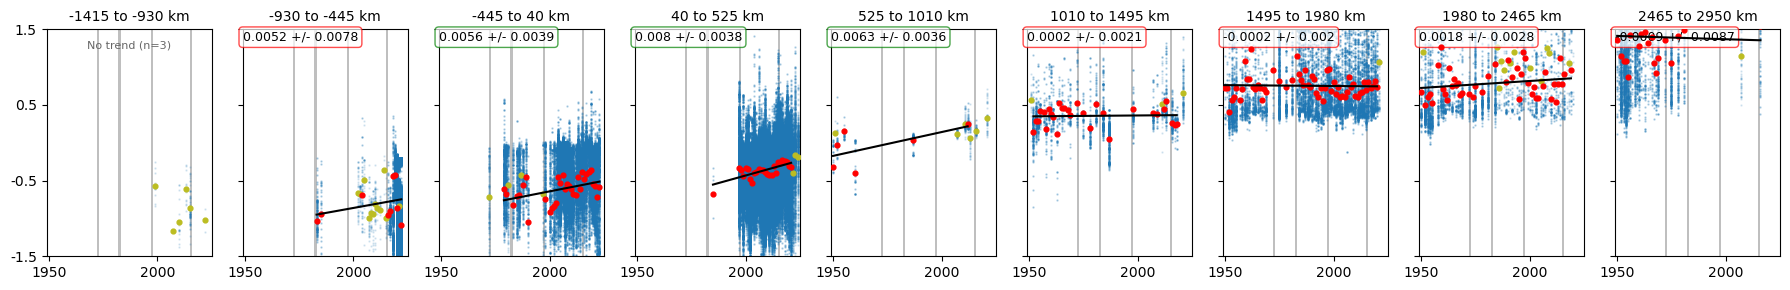

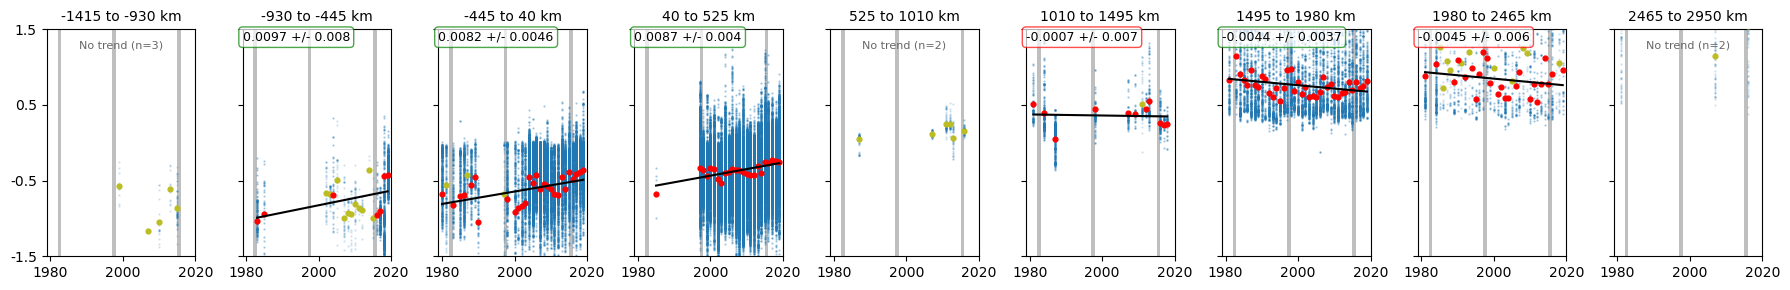

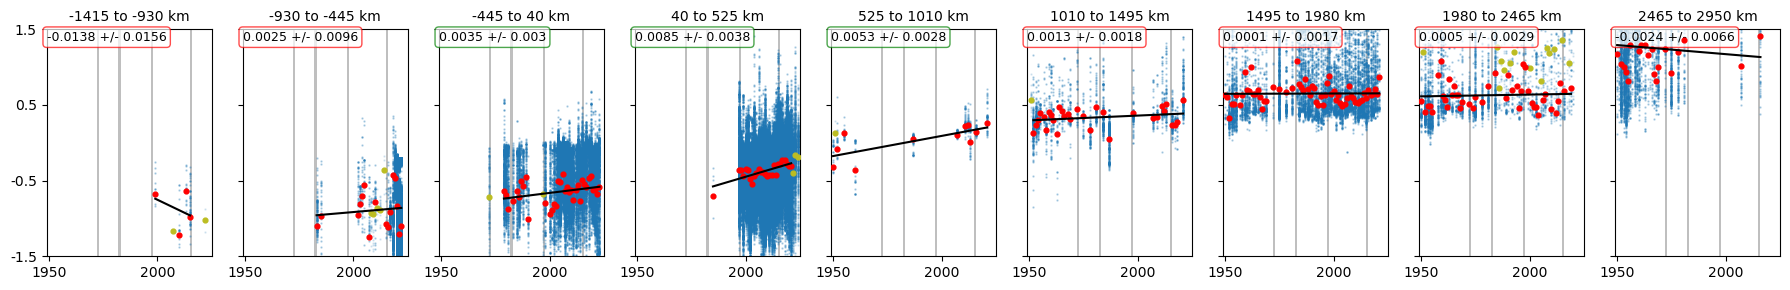

In [16]:
print('SPICE')
print('full range: 5 m binning')
trend_check(obs_shelf,'spice')
print('shortenned range:')
trend_check(obs_shelf[(obs_shelf.year>=yrmin)&(obs_shelf.year<yrmax)],'spice')

print('full range: 1 m binning')
trend_check(obs_shelf,'spice',depth_bin=1)

TEMPERATURE
full range:
temperature (degC): common depth range 0–60 m
Depth-eligible years: 238 / 285
Years used in regressions: 235
Trends calculated for 8 of 9 bins.
shortenned range:
temperature (degC): common depth range 0–60 m
Depth-eligible years: 140 / 174
Years used in regressions: 133
Trends calculated for 6 of 9 bins.
full range: 1 m binning
temperature (degC): common depth range 10–60 m
Depth-eligible years: 255 / 285
Years used in regressions: 255
Trends calculated for 9 of 9 bins.


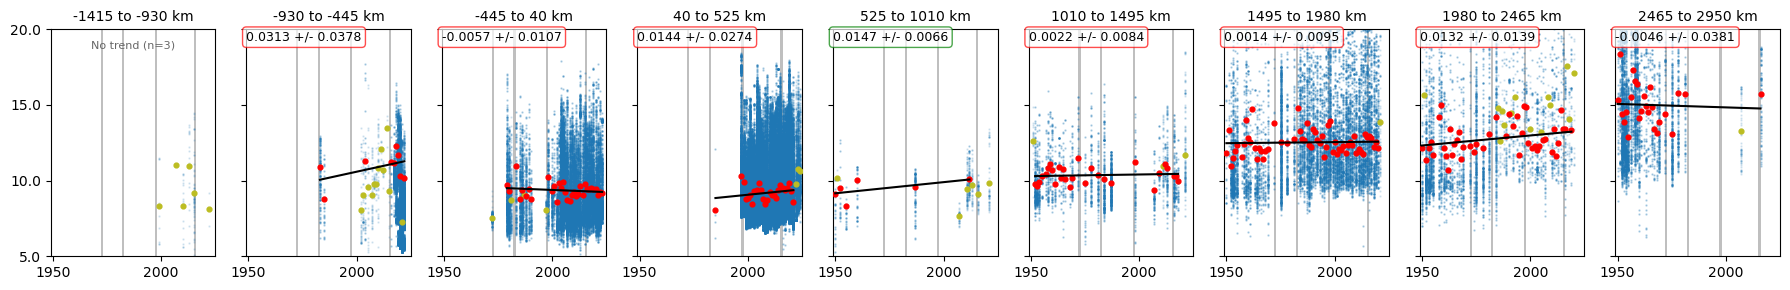

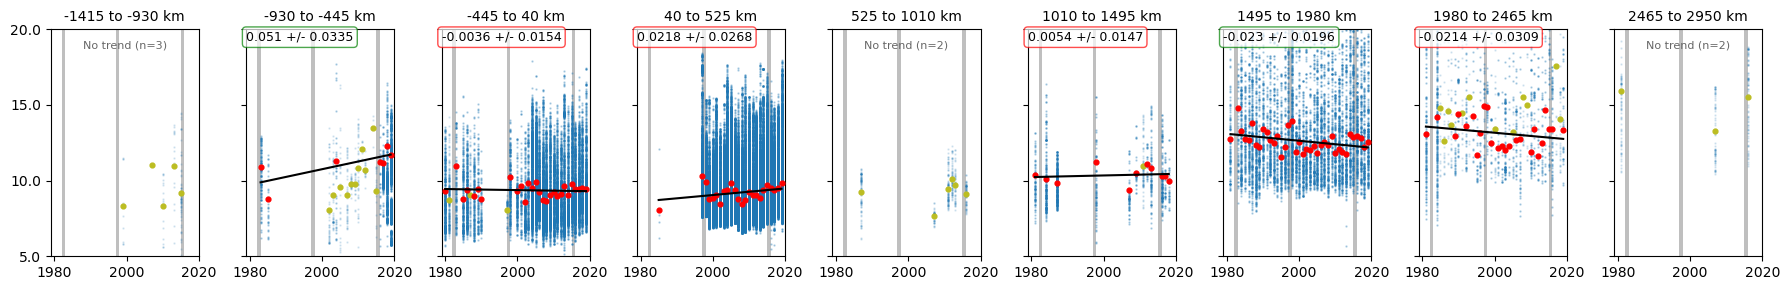

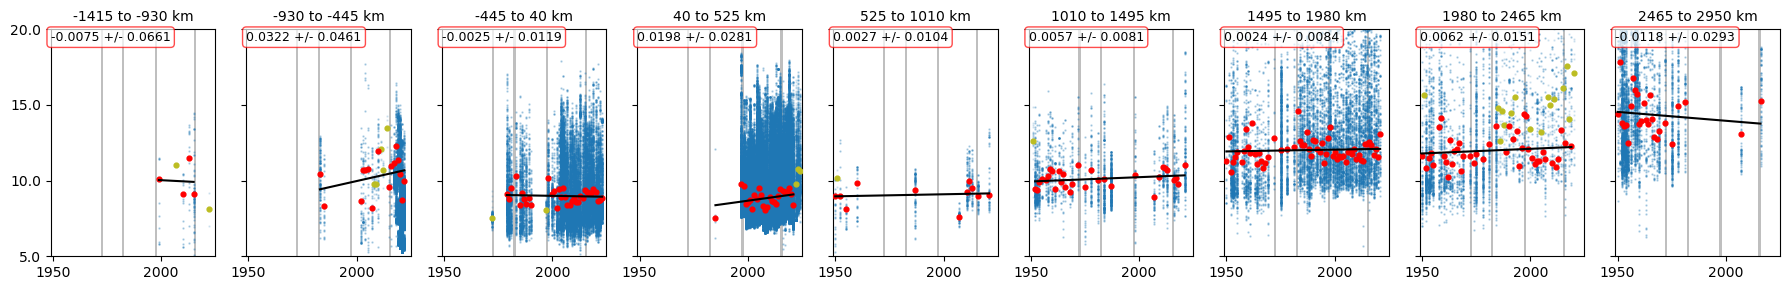

In [17]:
print('TEMPERATURE')
print('full range:')
trend_check(obs_shelf,'temperature (degC)')
print('shortenned range:')
trend_check(obs_shelf[(obs_shelf.year>=yrmin)&(obs_shelf.year<yrmax)],'temperature (degC)')

print('full range: 1 m binning')
trend_check(obs_shelf,'temperature (degC)',depth_bin=1)

SALINITY
full range:
salinity (g kg-1): common depth range 0–70 m
Depth-eligible years: 277 / 343
Years used in regressions: 277
Trends calculated for 9 of 9 bins.
shortenned range:
salinity (g kg-1): common depth range 10–60 m
Depth-eligible years: 161 / 182
Years used in regressions: 158
Trends calculated for 8 of 9 bins.
full range: 1 m binning
salinity (g kg-1): common depth range 10–70 m
Depth-eligible years: 297 / 343
Years used in regressions: 297
Trends calculated for 9 of 9 bins.


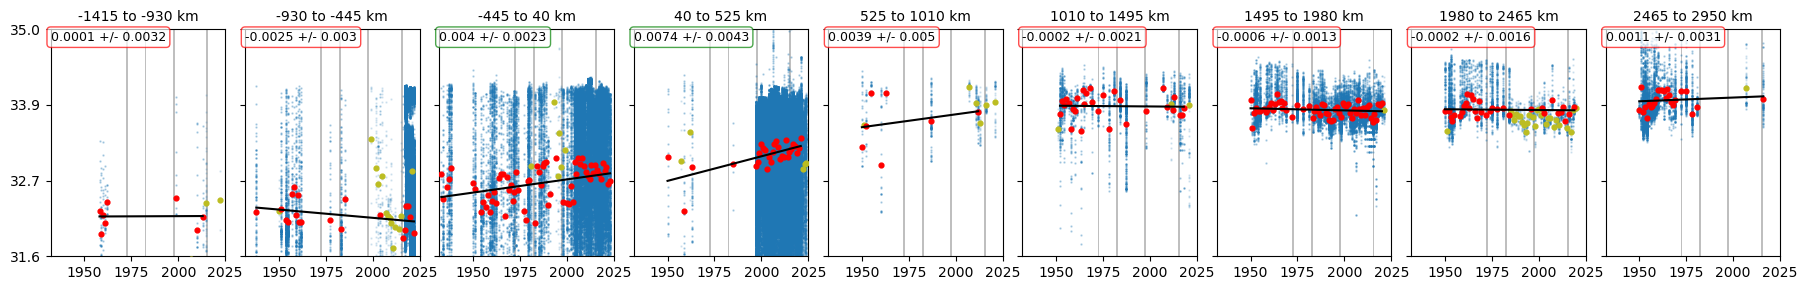

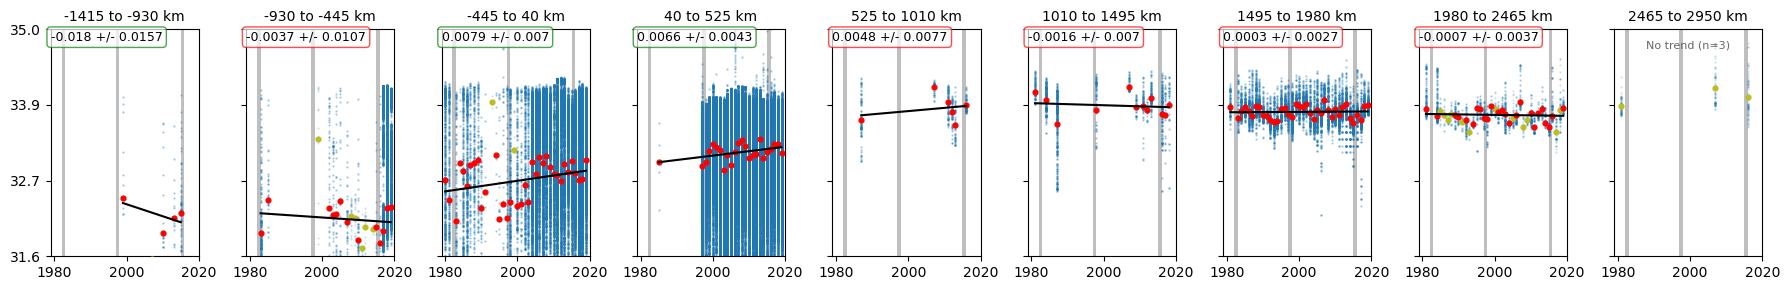

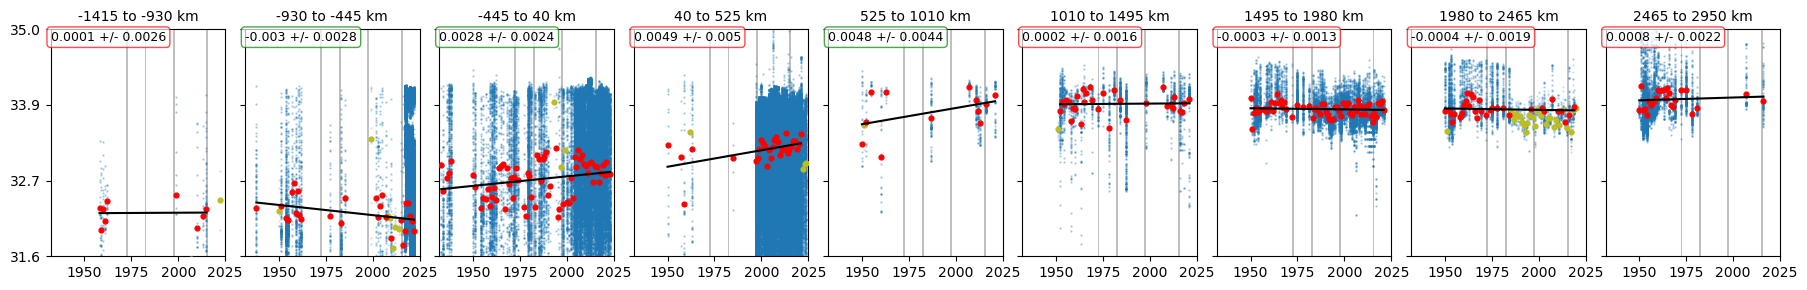

In [18]:
print('SALINITY')
print('full range:')
trend_check(obs_shelf,'salinity (g kg-1)')
print('shortenned range:')
trend_check(obs_shelf[(obs_shelf.year>=yrmin)&(obs_shelf.year<yrmax)],'salinity (g kg-1)')

print('full range: 1 m binning')
trend_check(obs_shelf,'salinity (g kg-1)',depth_bin=1)

OXYGEN
full range:
DO (umol kg-1): common depth range 10–60 m
Depth-eligible years: 237 / 267
Years used in regressions: 237
Trends calculated for 9 of 9 bins.
shortenned range:
DO (umol kg-1): common depth range 10–60 m
Depth-eligible years: 147 / 164
Years used in regressions: 145
Trends calculated for 8 of 9 bins.
full range: 1 m binning
DO (umol kg-1): common depth range 10–60 m
Depth-eligible years: 234 / 267
Years used in regressions: 234
Trends calculated for 9 of 9 bins.


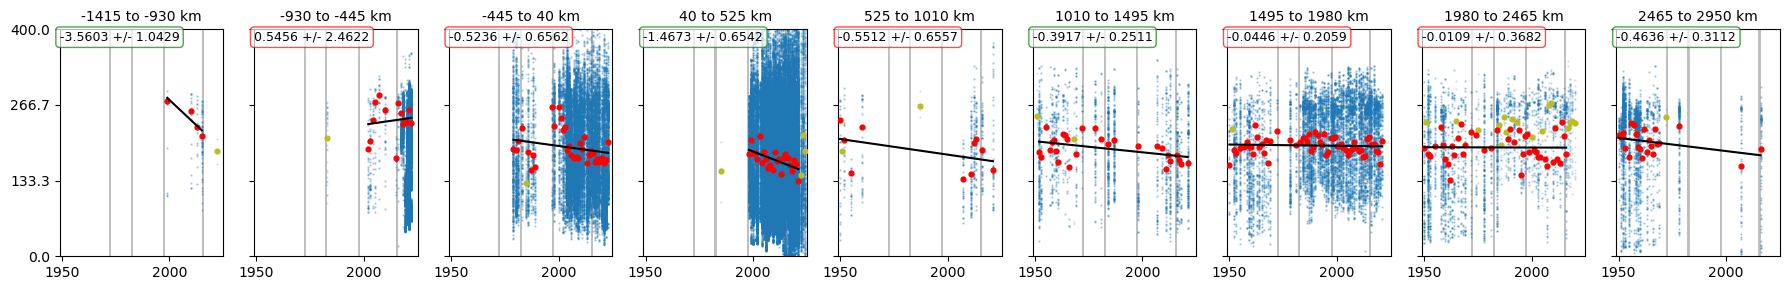

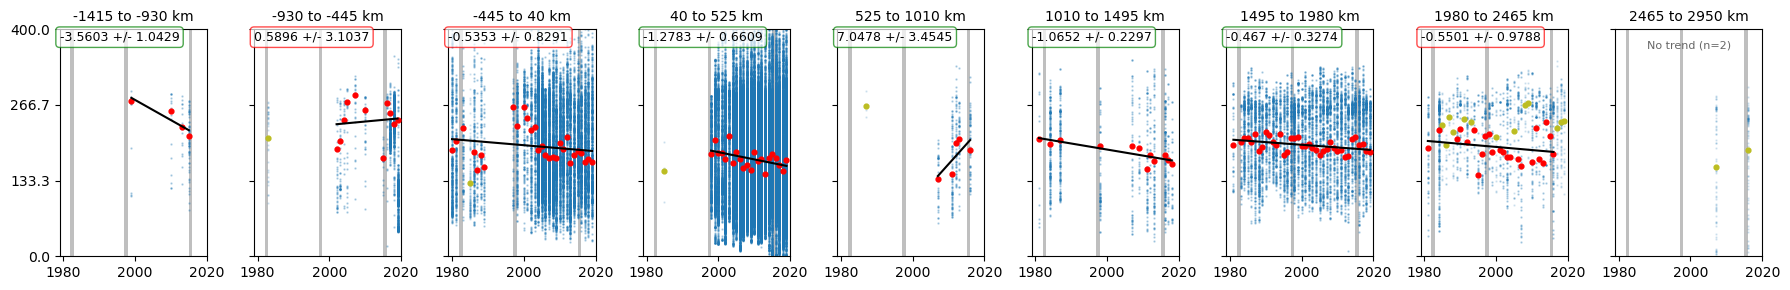

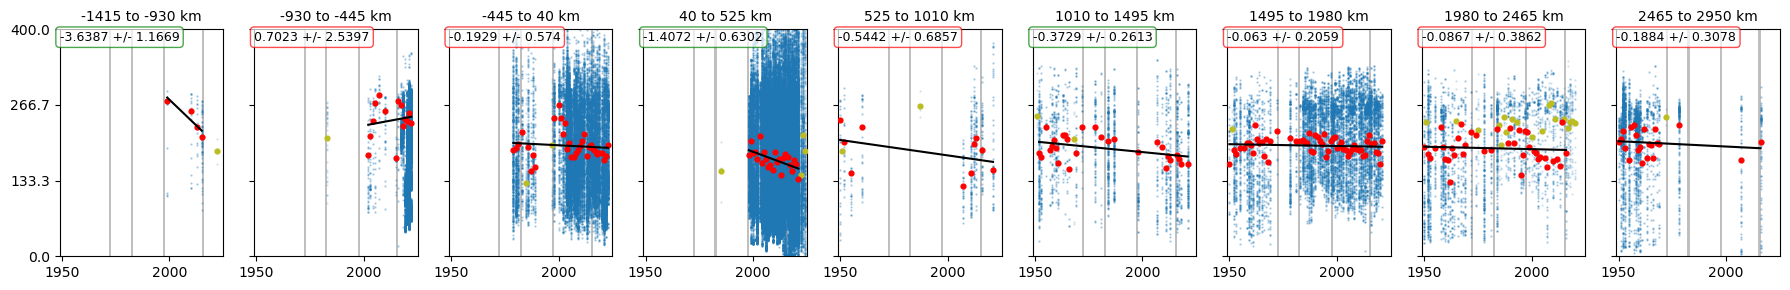

In [19]:
print('OXYGEN')
print('full range:')
trend_check(obs_shelf,'DO (umol kg-1)')
print('shortenned range:')
trend_check(obs_shelf[(obs_shelf.year>=yrmin)&(obs_shelf.year<yrmax)],'DO (umol kg-1)')

print('full range: 1 m binning')
trend_check(obs_shelf,'DO (umol kg-1)',depth_bin=1)

NITRATE
full range:
NO3 (uM): common depth range 10–60 m
Depth-eligible years: 156 / 187
Years used in regressions: 153
Trends calculated for 8 of 9 bins.
shortenned range:
NO3 (uM): common depth range 10–60 m
Depth-eligible years: 132 / 159
Years used in regressions: 127
Trends calculated for 7 of 9 bins.
full range: 1 m binning
NO3 (uM): common depth range 10–50 m
Depth-eligible years: 166 / 187
Years used in regressions: 163
Trends calculated for 8 of 9 bins.


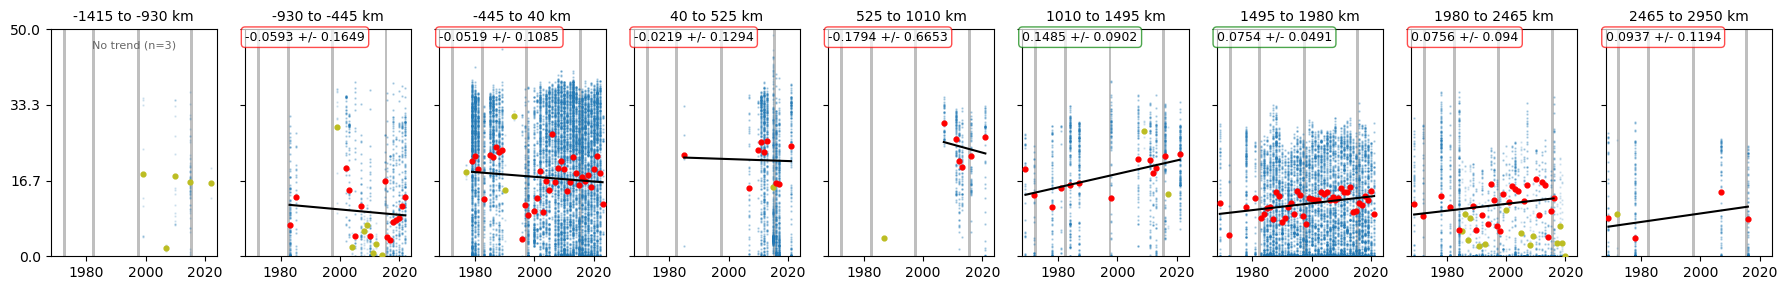

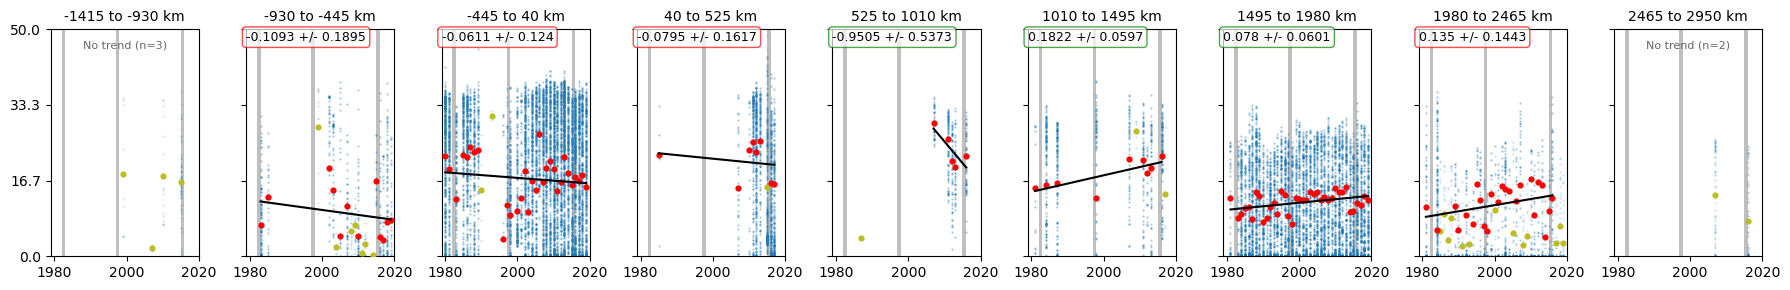

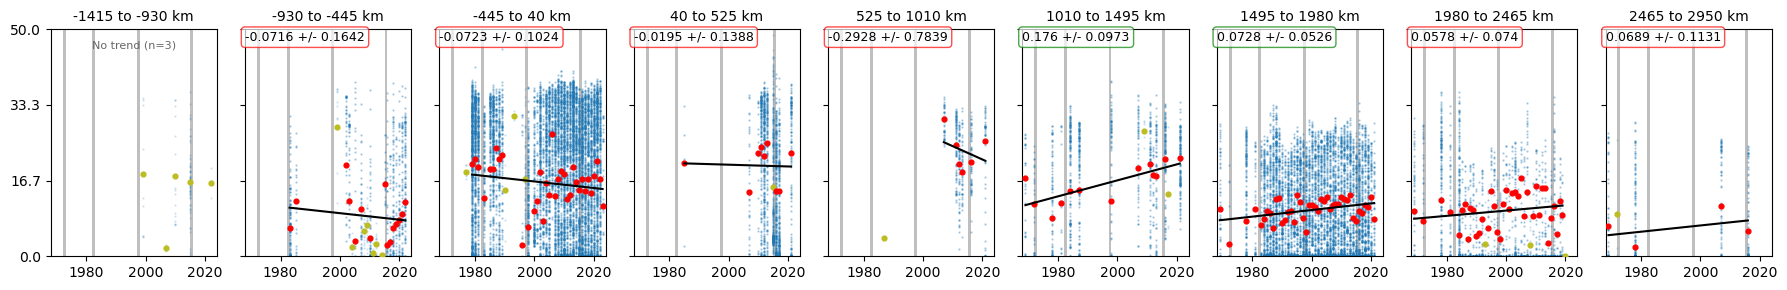

In [20]:
print('NITRATE')
print('full range:')
trend_check(obs_shelf,'NO3 (uM)')
print('shortenned range:')
trend_check(obs_shelf[(obs_shelf.year>=yrmin)&(obs_shelf.year<yrmax)],'NO3 (uM)')

print('full range: 1 m binning')
trend_check(obs_shelf,'NO3 (uM)',depth_bin=1)

[TA-DIC]
full range:
[TA-DIC] (uM): common depth range 10–90 m
Depth-eligible years: 43 / 53
Years used in regressions: 37
Trends calculated for 6 of 9 bins.
shortenned range:
[TA-DIC] (uM): common depth range 10–90 m
Depth-eligible years: 35 / 42
Years used in regressions: 23
Trends calculated for 4 of 9 bins.
full range: 1 m binning
[TA-DIC] (uM): common depth range 10–90 m
Depth-eligible years: 43 / 53
Years used in regressions: 37
Trends calculated for 6 of 9 bins.


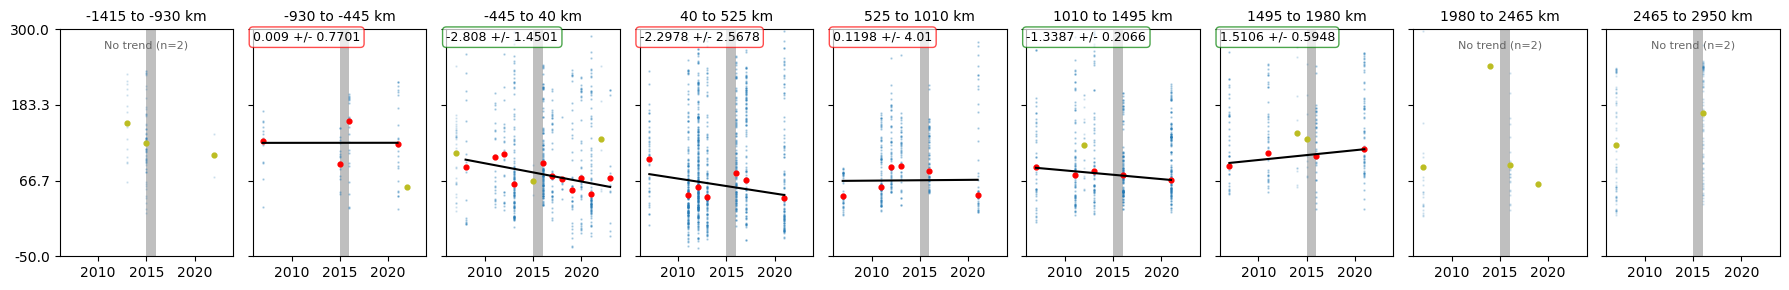

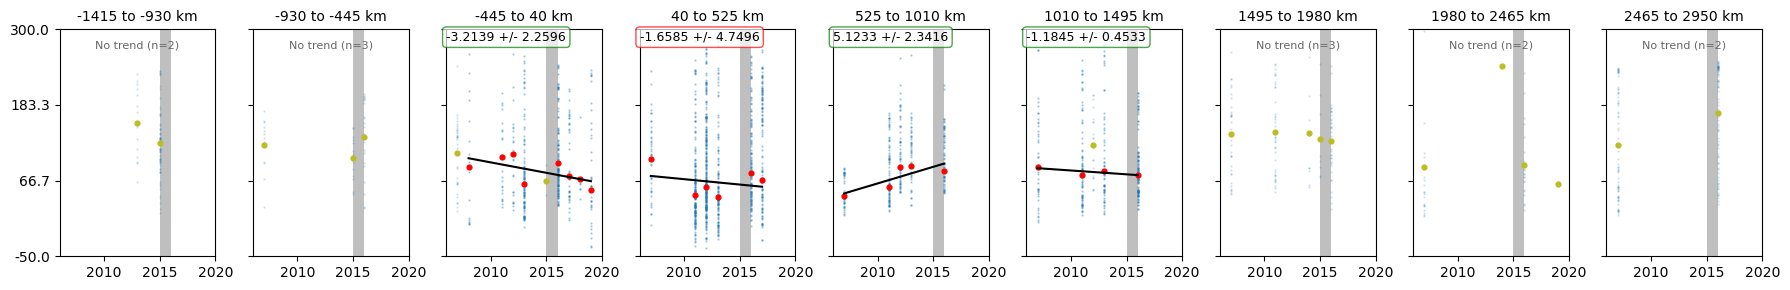

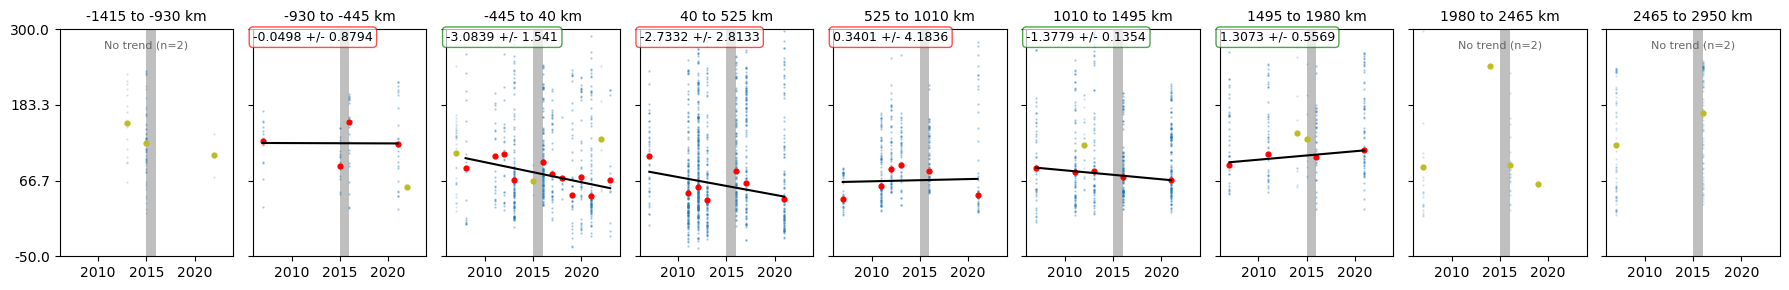

In [21]:
print('[TA-DIC]')
print('full range:')
trend_check(obs_shelf,'[TA-DIC] (uM)')
print('shortenned range:')
trend_check(obs_shelf[(obs_shelf.year>=yrmin)&(obs_shelf.year<yrmax)],'[TA-DIC] (uM)')

print('full range: 1 m binning')
trend_check(obs_shelf,'[TA-DIC] (uM)',depth_bin=1)

Shelf_Current | spice: common depth range 10–60 m
Retained 255 of 277 eligible annual profiles after depth filtering.
Estimated trends in 9 of 9 distance bins.
Shelf_Current | temperature (degC): common depth range 10–60 m
Retained 255 of 277 eligible annual profiles after depth filtering.
Estimated trends in 9 of 9 distance bins.
Shelf_Current | salinity (g kg-1): common depth range 10–70 m
Retained 297 of 334 eligible annual profiles after depth filtering.
Estimated trends in 9 of 9 distance bins.
Shelf_Current | DO (umol kg-1): common depth range 10–60 m
Retained 234 of 263 eligible annual profiles after depth filtering.
Estimated trends in 9 of 9 distance bins.
Shelf_Current | NO3 (uM): common depth range 10–50 m
Retained 166 of 177 eligible annual profiles after depth filtering.
Estimated trends in 8 of 9 distance bins.
Shelf_Current | [TA-DIC] (uM): common depth range 10–90 m
Retained 43 of 49 eligible annual profiles after depth filtering.
Estimated trends in 6 of 9 distance bin

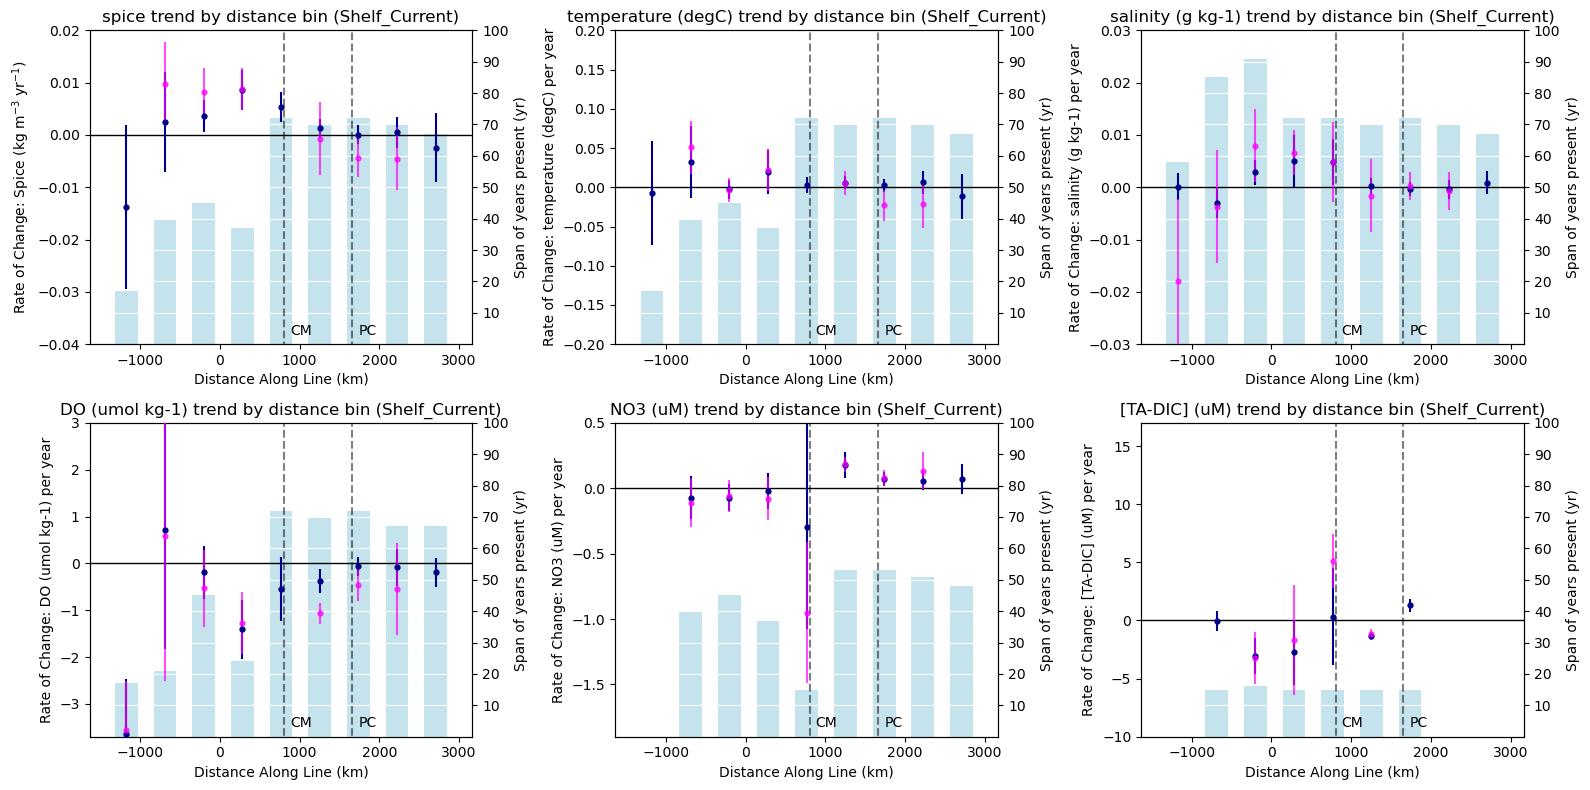

In [22]:
fig, ax = plt.subplots(2,3, figsize=(16, 8))

spice, diag_spice, annual_spice, _ = plot_ratediff_NS_CI('spice', 'Shelf_Current', (0,0),depth_bin=1)
temp, diag_temp, annual_temp, _ = plot_ratediff_NS_CI('temperature (degC)', 'Shelf_Current', (0,1),depth_bin=1)
salt, diag_salt, annual_salt, _ = plot_ratediff_NS_CI('salinity (g kg-1)', 'Shelf_Current', (0,2),depth_bin=1)
do, diag_do, annual_do, _ = plot_ratediff_NS_CI('DO (umol kg-1)', 'Shelf_Current', (1,0),depth_bin=1)
no3, diag_no3, annual_no3, _ = plot_ratediff_NS_CI('NO3 (uM)', 'Shelf_Current', (1,1),depth_bin=1)
tadic, diag_tadic, annual_tadic, _ = plot_ratediff_NS_CI('[TA-DIC] (uM)', 'Shelf_Current', (1,2),depth_bin=1)

_,_,_,_ = plot_ratediff_NS_CI('spice', 'Shelf_Current', (0,0),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('temperature (degC)', 'Shelf_Current', (0,1),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('salinity (g kg-1)', 'Shelf_Current', (0,2),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('DO (umol kg-1)', 'Shelf_Current', (1,0),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('NO3 (uM)', 'Shelf_Current', (1,1),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('[TA-DIC] (uM)', 'Shelf_Current', (1,2),bars=False)

plt.tight_layout()

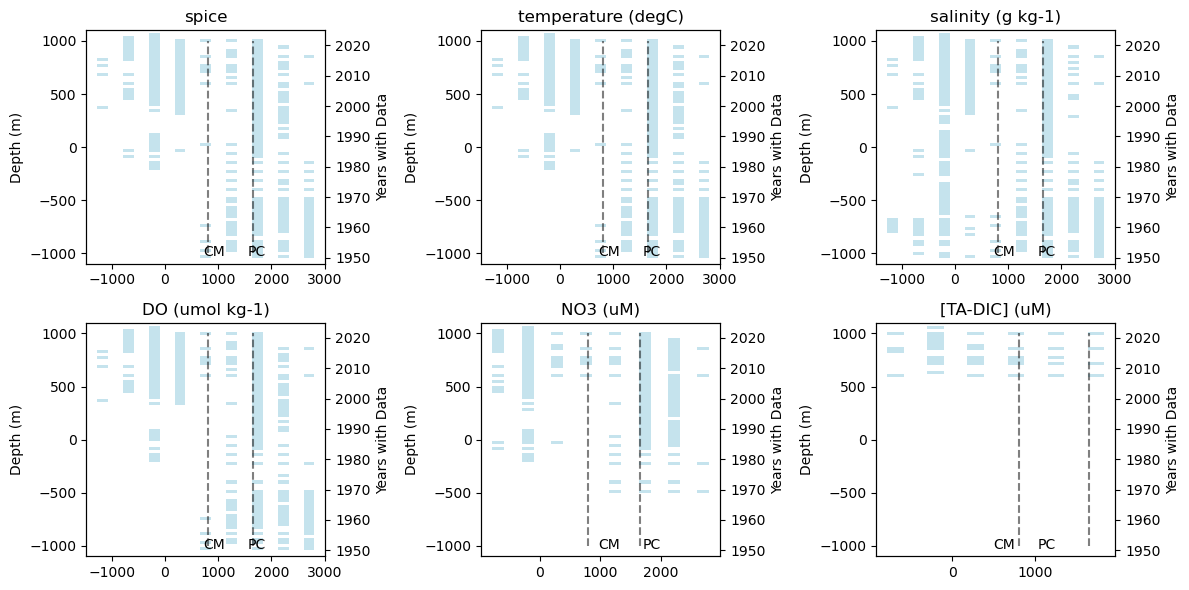

In [23]:
fig, ax = plt.subplots(2,3, figsize=(12, 6))
plot_years('spice', obs_shelf, (0,0),annual=annual_spice,diagnostics=diag_spice)
plot_years('temperature (degC)', obs_shelf, (0,1),annual=annual_temp,diagnostics=diag_temp)
plot_years('salinity (g kg-1)', obs_shelf, (0,2),annual=annual_salt,diagnostics=diag_salt)
plot_years('DO (umol kg-1)', obs_shelf, (1,0),annual=annual_do,diagnostics=diag_do)
plot_years('NO3 (uM)', obs_shelf, (1,1),annual=annual_no3,diagnostics=diag_no3)
plot_years('[TA-DIC] (uM)', obs_shelf, (1,2),annual=annual_tadic,diagnostics=diag_tadic)

plt.tight_layout()

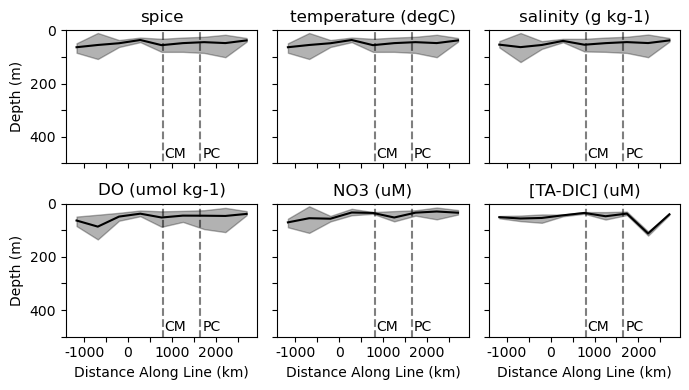

In [24]:
fig, ax = plt.subplots(2,3, figsize=(7, 4))
Dspice = plot_depth('spice', obs_shelf, (0,0),yax=True)
Dtemp = plot_depth('temperature (degC)', obs_shelf, (0,1))
Dsalt = plot_depth('salinity (g kg-1)', obs_shelf, (0,2))
Ddo = plot_depth('DO (umol kg-1)', obs_shelf, (1,0),yax=True,xax=True)
Dno3 = plot_depth('NO3 (uM)', obs_shelf, (1,1),xax=True)
Dtadic = plot_depth('[TA-DIC] (uM)', obs_shelf, (1,2),xax=True)

plt.tight_layout()

# plt.savefig('./output/shelfobsdepth.png')

In [25]:
# print difference in depth between the first and last bin
print(f'spice depth change = {Dspice[0]-Dspice[-1]}')
print(f'temp depth change = {Dtemp[0]-Dtemp[-1]}')
print(f'salt depth change = {Dsalt[0]-Dsalt[-1]}')
print(f'do depth change = {Ddo[0]-Ddo[-1]}')
print(f'no3 depth change = {Dno3[0]-Dno3[-1]}')
print(f'tadic depth change = {Dtadic[0]-Dtadic[-1]}')

spice depth change = 25.64820180727567
temp depth change = 25.64820180727567
salt depth change = 15.882897144627627
do depth change = 24.825852371798206
no3 depth change = 36.27227115362565
tadic depth change = 10.79462074698381


In [26]:
# check correlation between mean depth and the trends

print(f'spice: r = {pearsonr(spice,Dspice).statistic}, pvalue = {pearsonr(spice,Dspice).pvalue}')
print(f'temp: r = {pearsonr(temp,Dtemp).statistic}, pvalue = {pearsonr(temp,Dtemp).pvalue}')
print(f'salt: r = {pearsonr(salt,Dsalt).statistic}, pvalue = {pearsonr(salt,Dsalt).pvalue}')
print(f'do: r = {pearsonr(do,Ddo).statistic}, pvalue = {pearsonr(do,Ddo).pvalue}')
print(f'no3: r = {pearsonr(no3,Dno3).statistic}, pvalue = {pearsonr(no3,Dno3).pvalue}')
print(f'tadic: r = {pearsonr(tadic,Dtadic).statistic}, pvalue = {pearsonr(tadic,Dtadic).pvalue}')

spice: r = -0.5344237113089101, pvalue = 0.1382667323174743
temp: r = -0.018805696129978983, pvalue = 0.9617006392388914
salt: r = -0.3381331401766683, pvalue = 0.3734620123501625
do: r = 0.04231587260137109, pvalue = 0.9139233434680567
no3: r = nan, pvalue = nan
tadic: r = nan, pvalue = nan


In [27]:
print_ratediff_NS_CI(obs_shelf,depth_bin=1)


spice
Common depth range: 10–60 m
-1415 to -930 km & -0.0138 & 0.0156 & 1999-2015 & 113
-930 to -445 km & 0.0025 & 0.0096 & 1983-2022 & 13726
-445 to 40 km & 0.0035 & 0.0030 & 1979-2023 & 30159
40 to 525 km & 0.0085 & 0.0038 & 1985-2021 & 140511
525 to 1010 km & 0.0053 & 0.0028 & 1950-2021 & 547
1010 to 1495 km & 0.0013 & 0.0018 & 1952-2021 & 2446
1495 to 1980 km & 0.0001 & 0.0017 & 1950-2021 & 11179
1980 to 2465 km & 0.0005 & 0.0029 & 1950-2019 & 3509
2465 to 2950 km & -0.0024 & 0.0066 & 1950-2016 & 4753

temperature (degC)
Common depth range: 10–60 m
-1415 to -930 km & -0.0075 & 0.0661 & 1999-2015 & 113
-930 to -445 km & 0.0322 & 0.0461 & 1983-2022 & 13726
-445 to 40 km & -0.0025 & 0.0119 & 1979-2023 & 30159
40 to 525 km & 0.0198 & 0.0281 & 1985-2021 & 140511
525 to 1010 km & 0.0027 & 0.0104 & 1950-2021 & 547
1010 to 1495 km & 0.0057 & 0.0081 & 1952-2021 & 2446
1495 to 1980 km & 0.0024 & 0.0084 & 1950-2021 & 11179
1980 to 2465 km & 0.0062 & 0.0151 & 1950-2019 & 3509
2465 to 2950 km 

# CC

SPICE
full range:
spice: common depth range 0–120 m
Depth-eligible years: 295 / 352
Years used in regressions: 295
Trends calculated for 9 of 9 bins.
shortenned range:
spice: common depth range 10–100 m
Depth-eligible years: 204 / 209
Years used in regressions: 204
Trends calculated for 9 of 9 bins.
full range: 1 m binning
spice: common depth range 10–120 m
Depth-eligible years: 314 / 352
Years used in regressions: 314
Trends calculated for 9 of 9 bins.


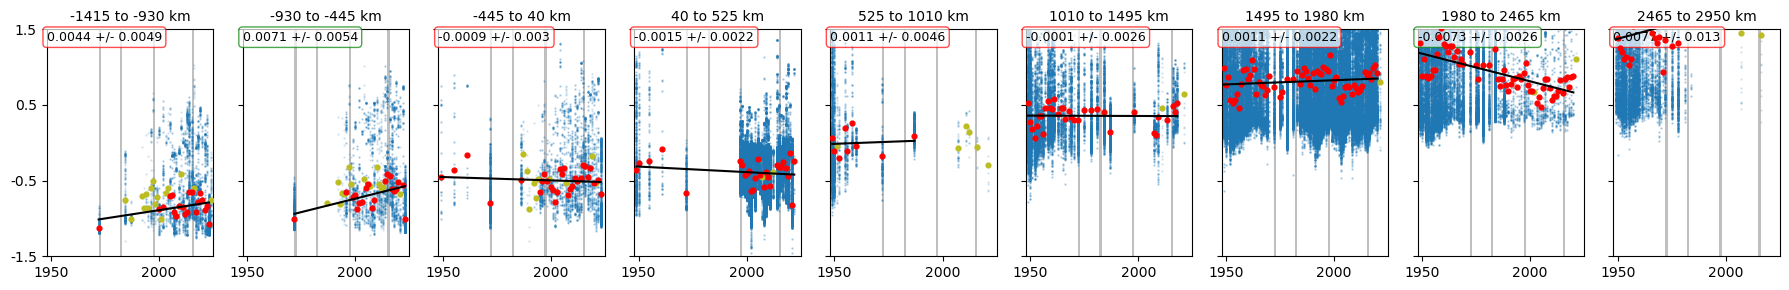

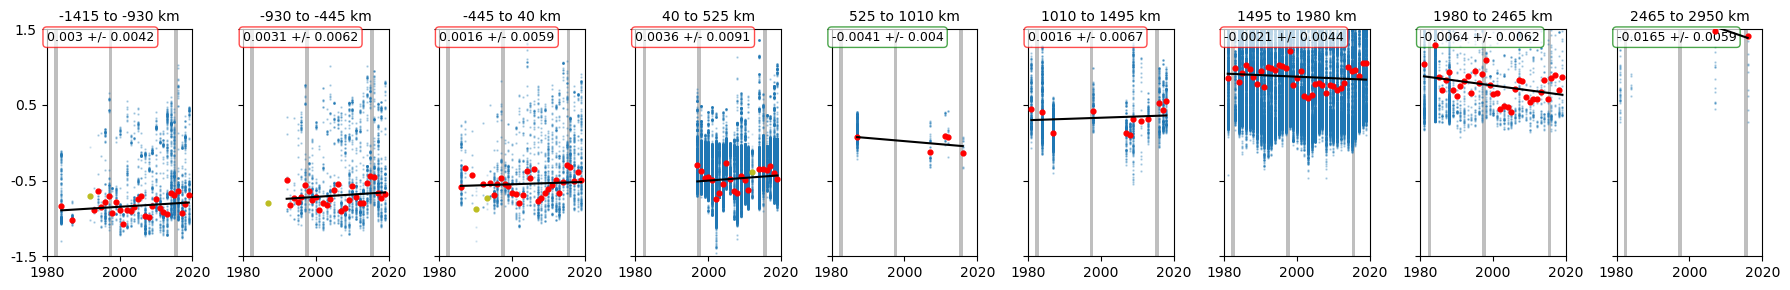

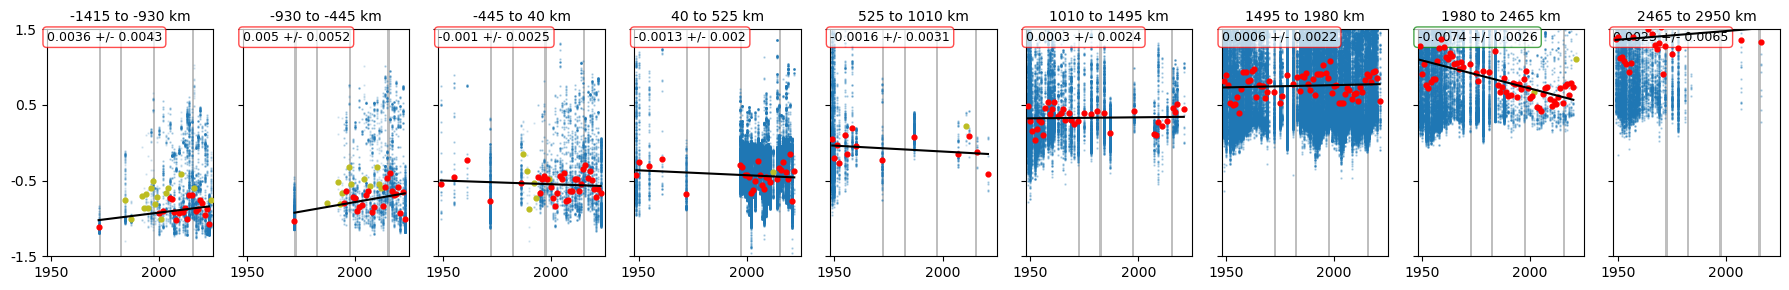

In [28]:
print('SPICE')
print('full range:')
trend_check(obs_cc,'spice')
print('shortenned range:')
trend_check(obs_cc[(obs_cc.year>=yrmin)&(obs_cc.year<yrmax)],'spice')

print('full range: 1 m binning')
trend_check(obs_cc,'spice',depth_bin=1)

TEMPERATURE
full range:
temperature (degC): common depth range 0–120 m
Depth-eligible years: 295 / 352
Years used in regressions: 295
Trends calculated for 9 of 9 bins.
shortenned range:
temperature (degC): common depth range 10–100 m
Depth-eligible years: 204 / 209
Years used in regressions: 204
Trends calculated for 9 of 9 bins.
full range: 1 m binning
temperature (degC): common depth range 10–120 m
Depth-eligible years: 314 / 352
Years used in regressions: 314
Trends calculated for 9 of 9 bins.


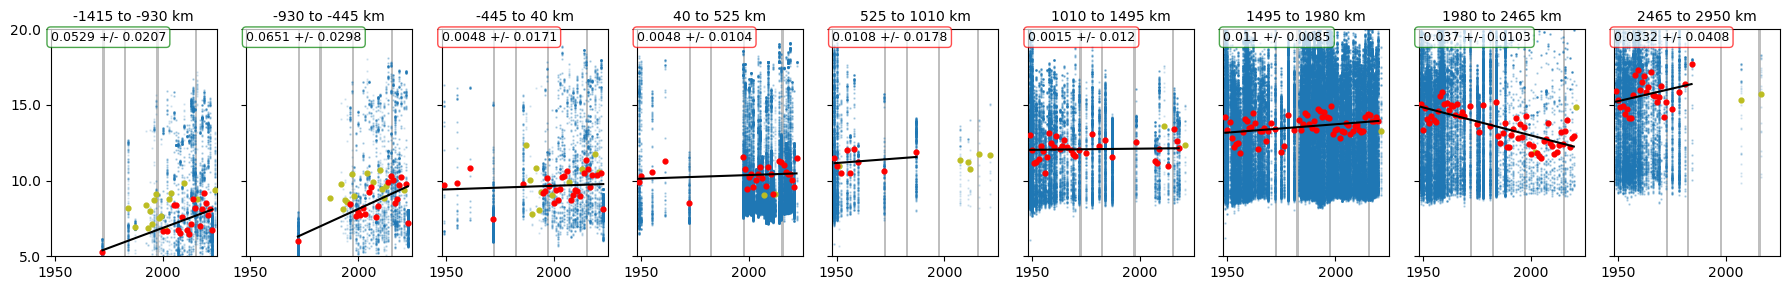

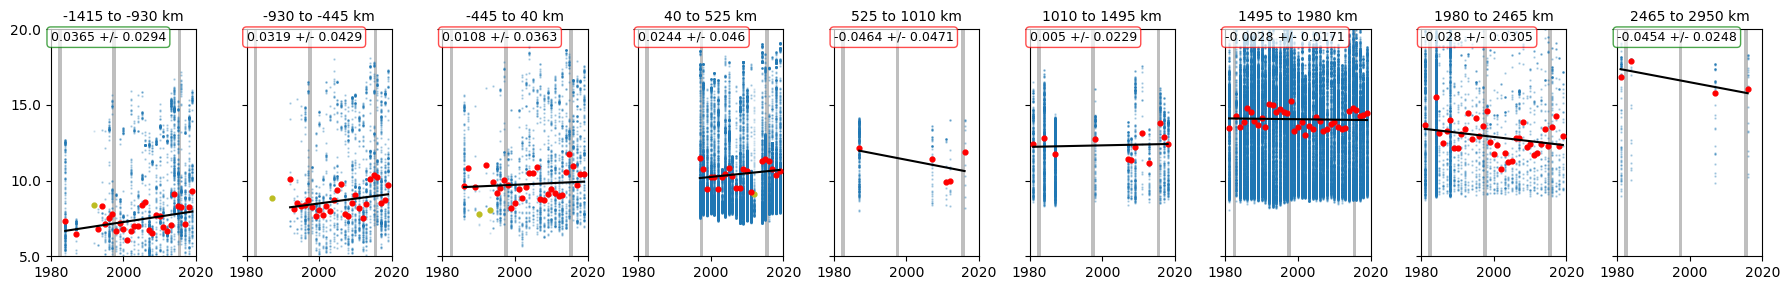

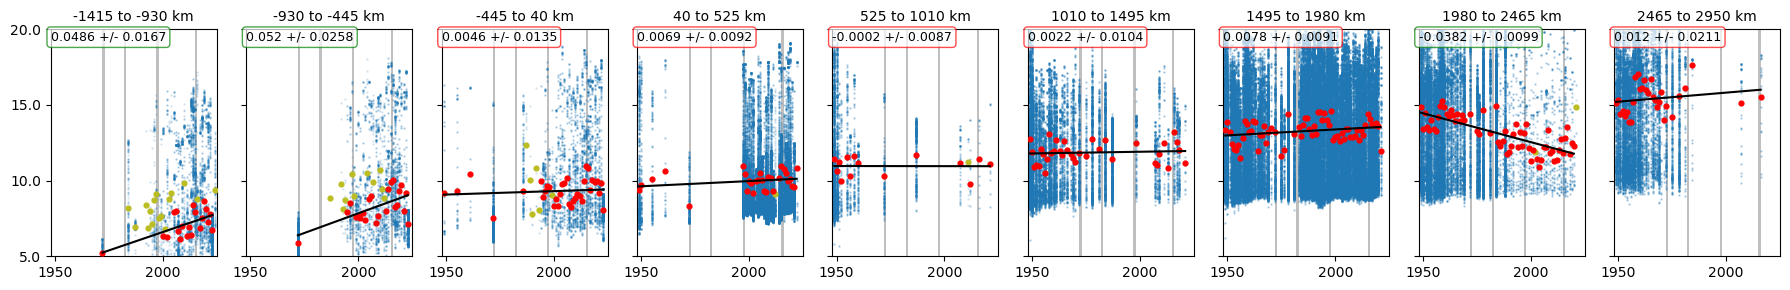

In [29]:
print('TEMPERATURE')
print('full range:')
trend_check(obs_cc,'temperature (degC)')
print('shortenned range:')
trend_check(obs_cc[(obs_cc.year>=yrmin)&(obs_cc.year<yrmax)],'temperature (degC)')

print('full range: 1 m binning')
trend_check(obs_cc,'temperature (degC)',depth_bin=1)

SALINITY
full range:
salinity (g kg-1): common depth range 0–120 m
Depth-eligible years: 295 / 352
Years used in regressions: 295
Trends calculated for 9 of 9 bins.
shortenned range:
salinity (g kg-1): common depth range 10–100 m
Depth-eligible years: 204 / 209
Years used in regressions: 204
Trends calculated for 9 of 9 bins.
full range: 1 m binning
salinity (g kg-1): common depth range 10–120 m
Depth-eligible years: 314 / 352
Years used in regressions: 314
Trends calculated for 9 of 9 bins.


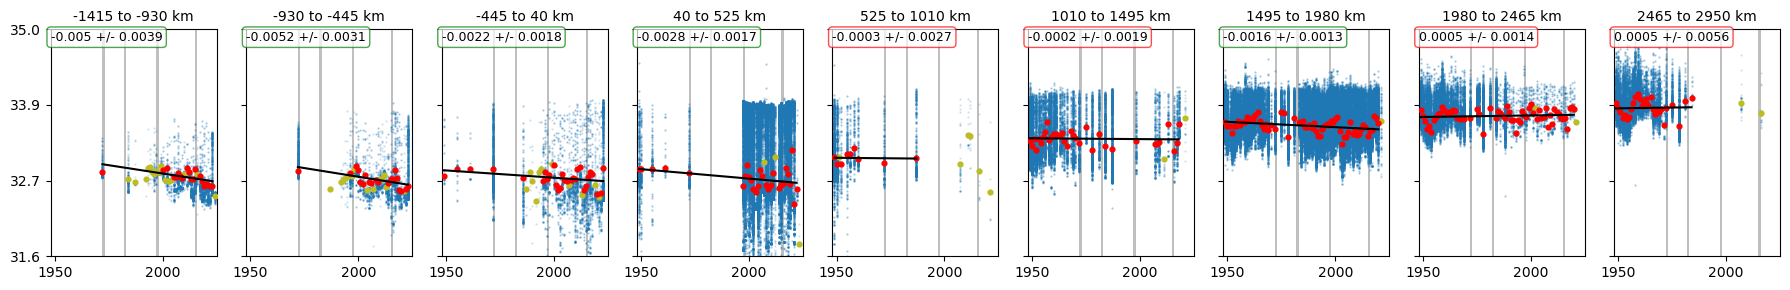

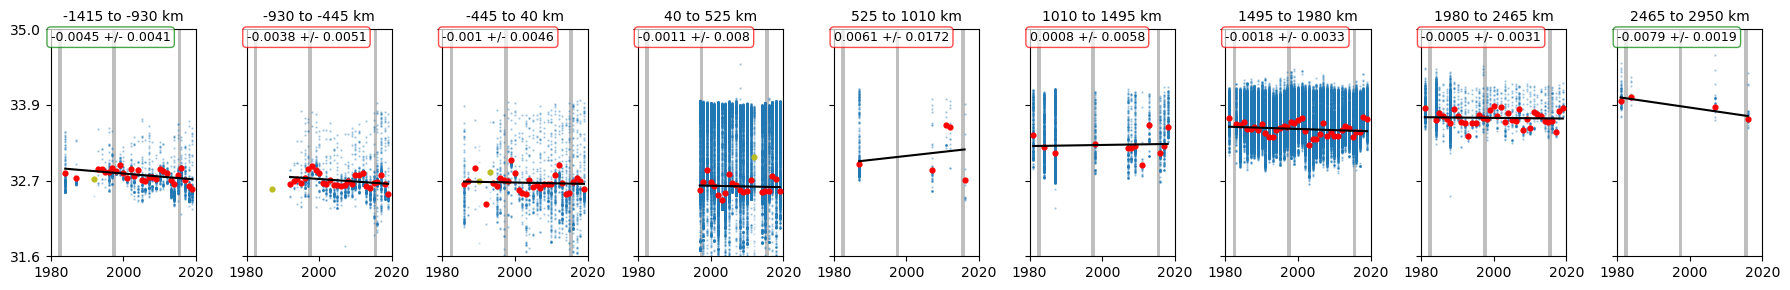

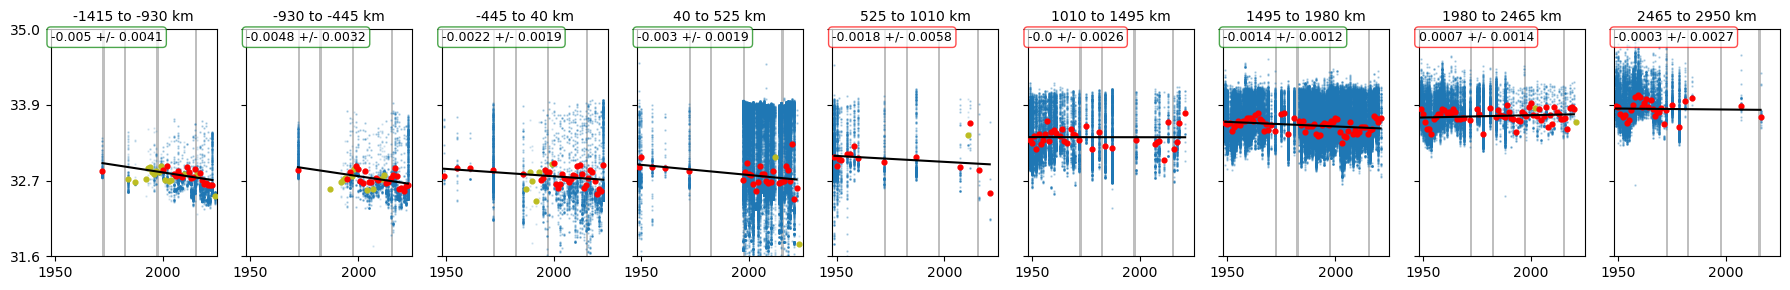

In [30]:
print('SALINITY')
print('full range:')
trend_check(obs_cc,'salinity (g kg-1)')
print('shortenned range:')
trend_check(obs_cc[(obs_cc.year>=yrmin)&(obs_cc.year<yrmax)],'salinity (g kg-1)')

print('full range: 1 m binning')
trend_check(obs_cc,'salinity (g kg-1)',depth_bin=1)

OXYGEN
full range:
DO (umol kg-1): common depth range 0–120 m
Depth-eligible years: 281 / 336
Years used in regressions: 281
Trends calculated for 9 of 9 bins.
shortenned range:
DO (umol kg-1): common depth range 10–100 m
Depth-eligible years: 197 / 200
Years used in regressions: 194
Trends calculated for 8 of 9 bins.
full range: 1 m binning
DO (umol kg-1): common depth range 10–120 m
Depth-eligible years: 303 / 336
Years used in regressions: 303
Trends calculated for 9 of 9 bins.


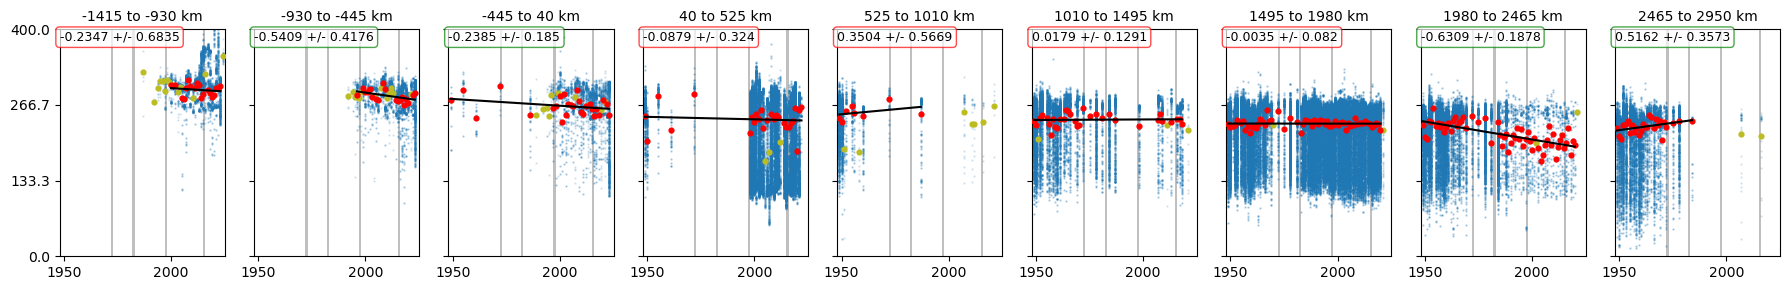

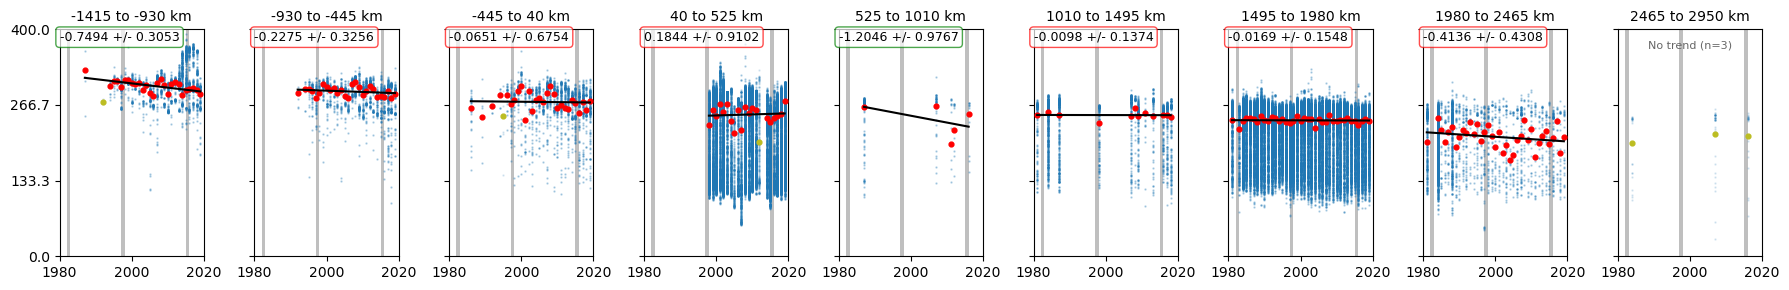

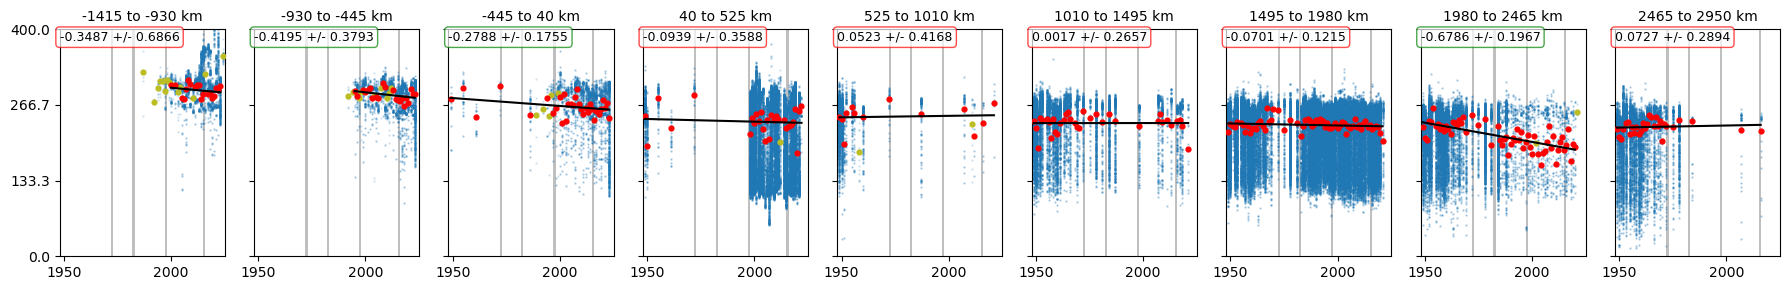

In [31]:
print('OXYGEN')

print('full range:')
trend_check(obs_cc,'DO (umol kg-1)')
print('shortenned range:')
trend_check(obs_cc[(obs_cc.year>=yrmin)&(obs_cc.year<yrmax)],'DO (umol kg-1)')

print('full range: 1 m binning')
trend_check(obs_cc,'DO (umol kg-1)',depth_bin=1)

NITRATE
full range:
NO3 (uM): common depth range 10–100 m
Depth-eligible years: 215 / 222
Years used in regressions: 215
Trends calculated for 9 of 9 bins.
shortenned range:
NO3 (uM): common depth range 10–100 m
Depth-eligible years: 176 / 182
Years used in regressions: 170
Trends calculated for 7 of 9 bins.
full range: 1 m binning
NO3 (uM): common depth range 10–100 m
Depth-eligible years: 214 / 222
Years used in regressions: 214
Trends calculated for 9 of 9 bins.


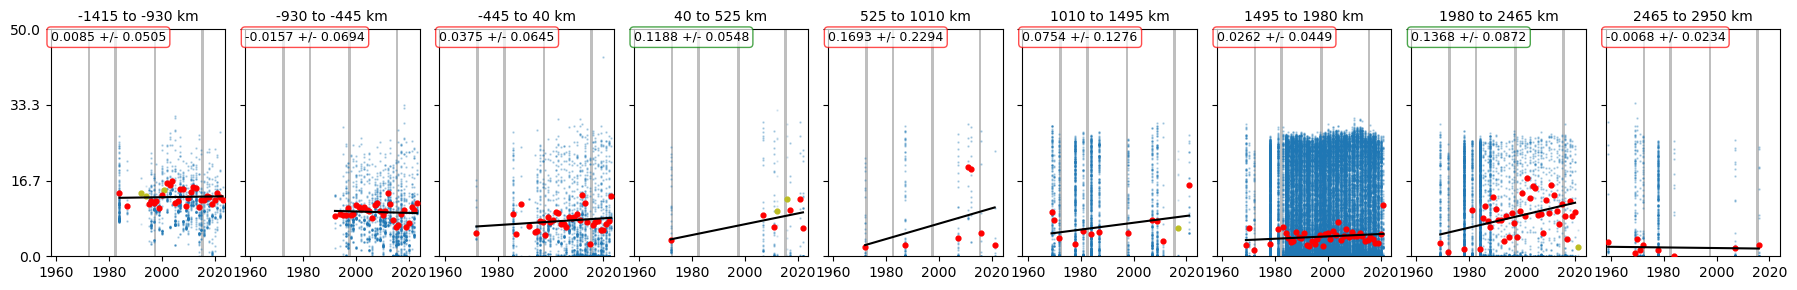

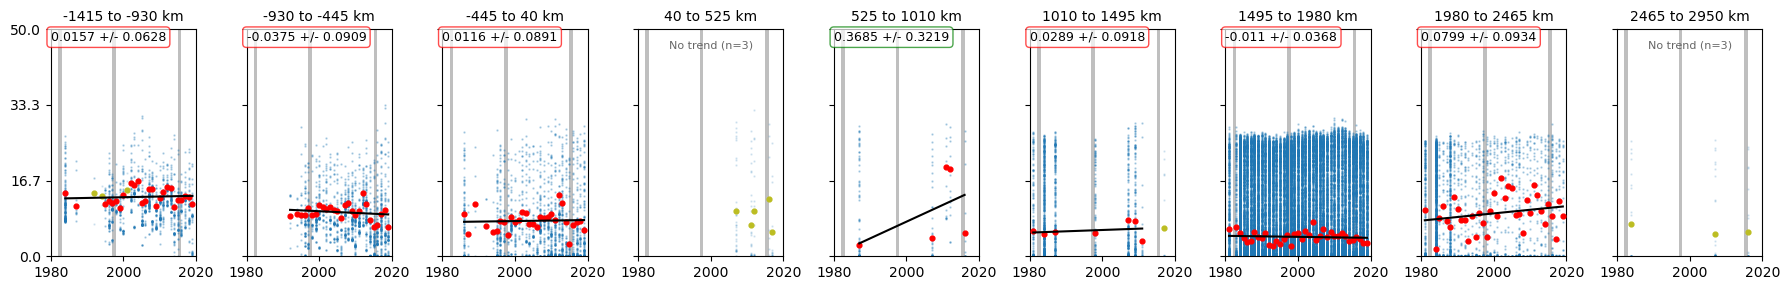

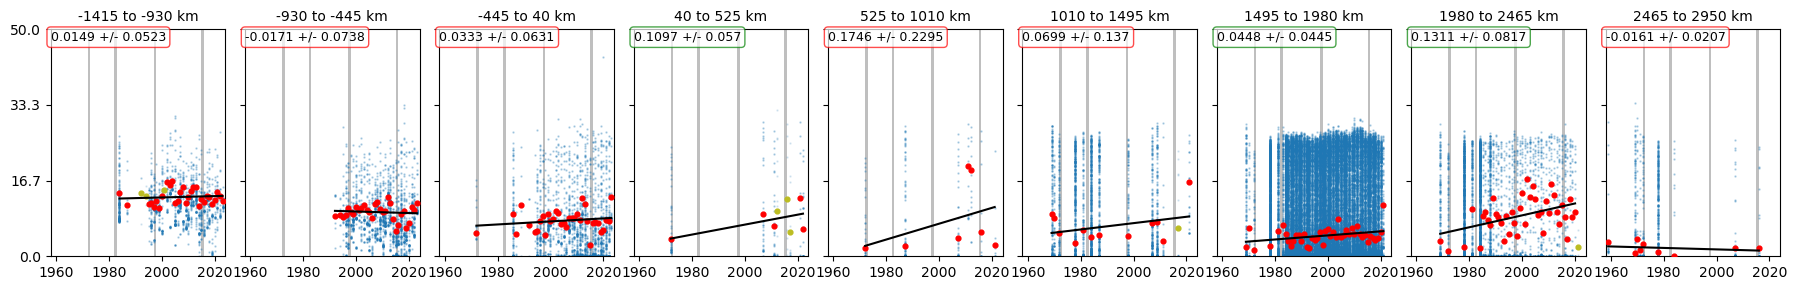

In [32]:
print('NITRATE')

print('full range:')
trend_check(obs_cc,'NO3 (uM)')
print('shortenned range:')
trend_check(obs_cc[(obs_cc.year>=yrmin)&(obs_cc.year<yrmax)],'NO3 (uM)')

print('full range: 1 m binning')
trend_check(obs_cc,'NO3 (uM)',depth_bin=1)

[TA-DIC]
full range:
[TA-DIC] (uM): common depth range 10–100 m
Depth-eligible years: 40 / 44
Years used in regressions: 29
Trends calculated for 4 of 9 bins.
shortenned range:
[TA-DIC] (uM): common depth range 10–100 m
Depth-eligible years: 35 / 39
Years used in regressions: 22
Trends calculated for 3 of 9 bins.
full range: 1 m binning
[TA-DIC] (uM): common depth range 10–90 m
Depth-eligible years: 38 / 44
Years used in regressions: 24
Trends calculated for 3 of 9 bins.


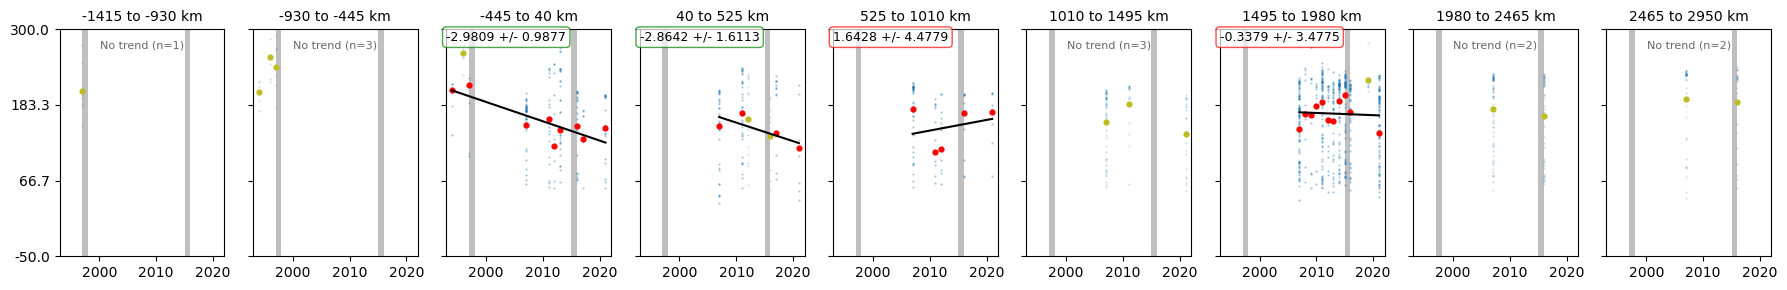

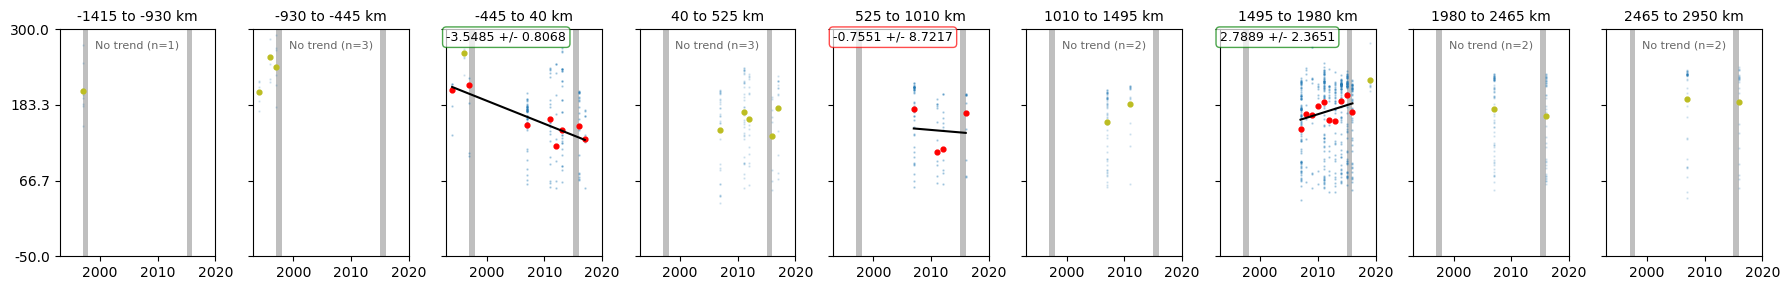

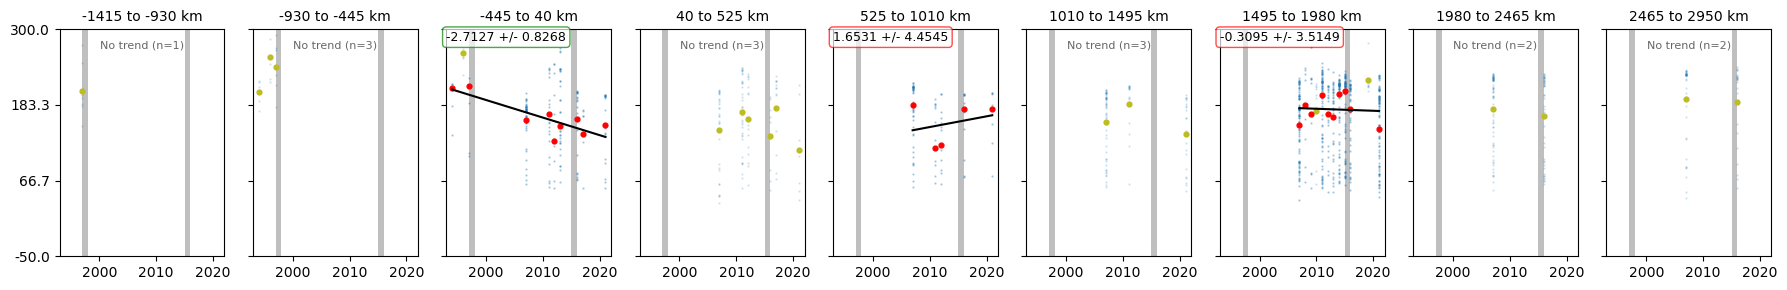

In [33]:
print('[TA-DIC]')
print('full range:')
trend_check(obs_cc,'[TA-DIC] (uM)')
print('shortenned range:')
trend_check(obs_cc[(obs_cc.year>=yrmin)&(obs_cc.year<yrmax)],'[TA-DIC] (uM)')

print('full range: 1 m binning')
trend_check(obs_cc,'[TA-DIC] (uM)',depth_bin=1)

CC | spice: common depth range 10–120 m
Retained 314 of 349 eligible annual profiles after depth filtering.
Estimated trends in 9 of 9 distance bins.
CC | temperature (degC): common depth range 10–120 m
Retained 314 of 349 eligible annual profiles after depth filtering.
Estimated trends in 9 of 9 distance bins.
CC | salinity (g kg-1): common depth range 10–120 m
Retained 314 of 349 eligible annual profiles after depth filtering.
Estimated trends in 9 of 9 distance bins.
CC | DO (umol kg-1): common depth range 10–120 m
Retained 303 of 335 eligible annual profiles after depth filtering.
Estimated trends in 9 of 9 distance bins.
CC | NO3 (uM): common depth range 10–100 m
Retained 214 of 221 eligible annual profiles after depth filtering.
Estimated trends in 9 of 9 distance bins.
CC | [TA-DIC] (uM): common depth range 10–90 m
Retained 38 of 44 eligible annual profiles after depth filtering.
Estimated trends in 3 of 9 distance bins.
CC | spice: common depth range 10–100 m
Retained 204 of 20

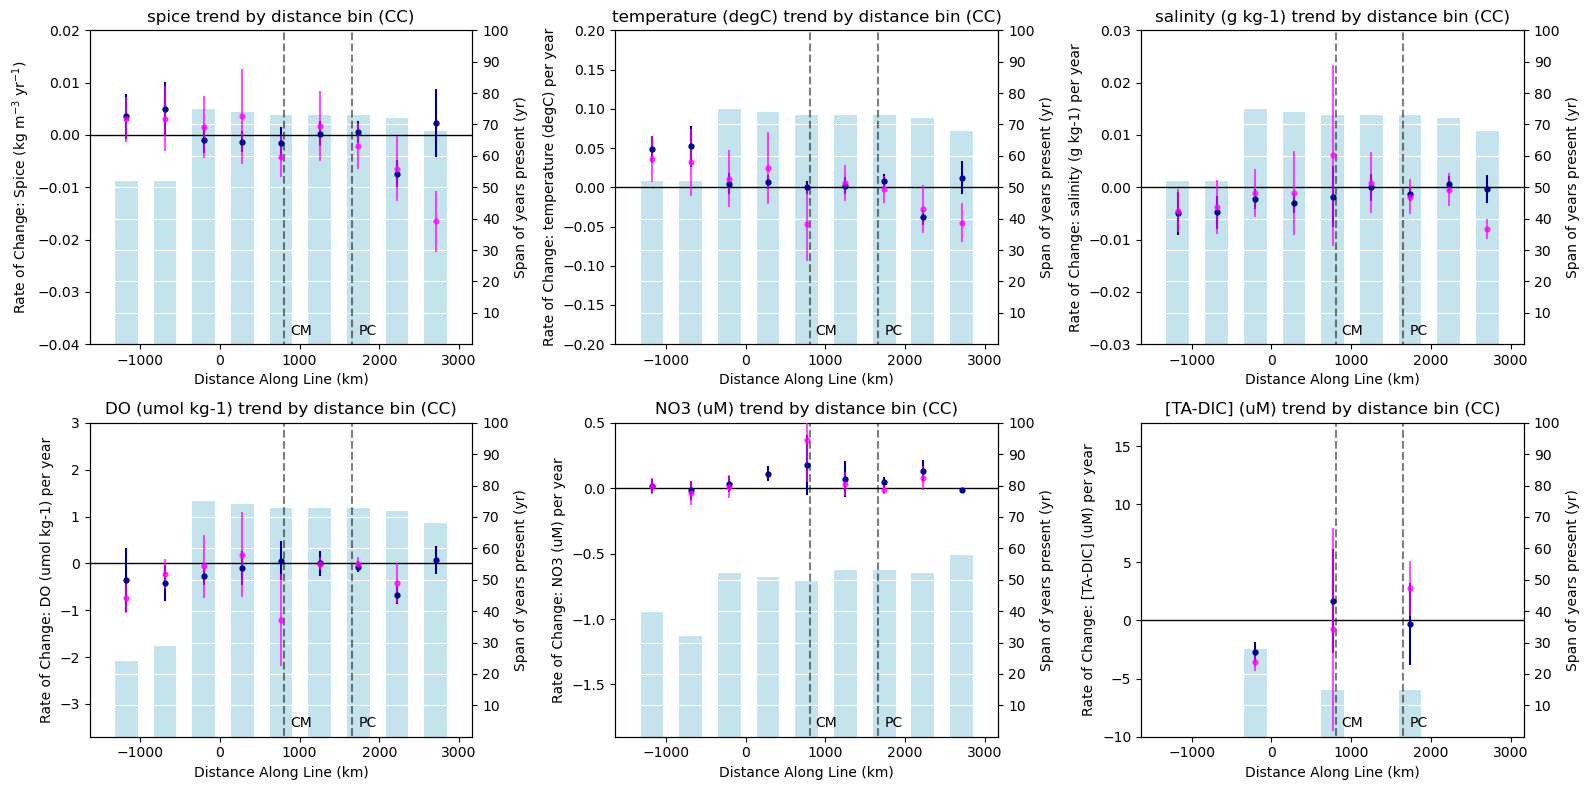

In [40]:
fig, ax = plt.subplots(2,3, figsize=(16, 8))

spice, diag_spice, annual_spice, _ = plot_ratediff_NS_CI('spice', 'CC', (0,0),depth_bin=1)
temp, diag_temp, annual_temp, _ = plot_ratediff_NS_CI('temperature (degC)', 'CC', (0,1),depth_bin=1)
salt, diag_salt, annual_salt, _ = plot_ratediff_NS_CI('salinity (g kg-1)', 'CC', (0,2),depth_bin=1)
do, diag_do, annual_do, _ = plot_ratediff_NS_CI('DO (umol kg-1)', 'CC', (1,0),depth_bin=1)
no3, diag_no3, annual_no3, _ = plot_ratediff_NS_CI('NO3 (uM)', 'CC', (1,1),depth_bin=1)
tadic, diag_tadic, annual_tadic, _ = plot_ratediff_NS_CI('[TA-DIC] (uM)', 'CC', (1,2),depth_bin=1)

_,_,_,_ = plot_ratediff_NS_CI('spice', 'CC', (0,0),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('temperature (degC)', 'CC', (0,1),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('salinity (g kg-1)', 'CC', (0,2),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('DO (umol kg-1)', 'CC', (1,0),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('NO3 (uM)', 'CC', (1,1),bars=False)
_,_,_,_ = plot_ratediff_NS_CI('[TA-DIC] (uM)', 'CC', (1,2),bars=False)

plt.tight_layout()

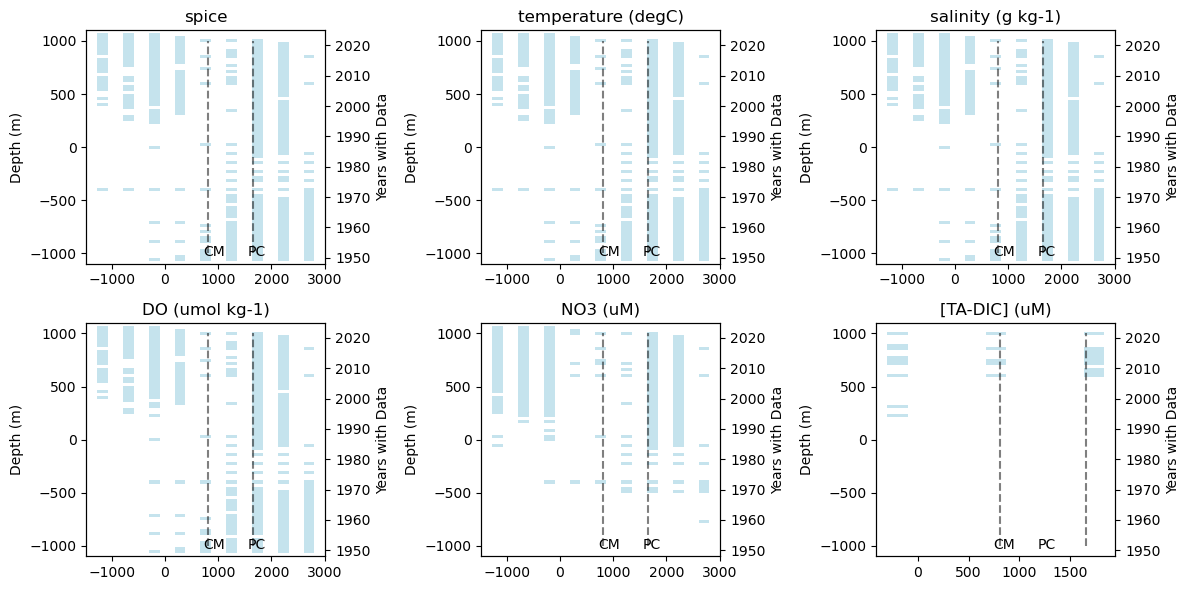

In [41]:
fig, ax = plt.subplots(2,3, figsize=(12, 6))
plot_years('spice', obs_cc, (0,0),annual=annual_spice,diagnostics=diag_spice)
plot_years('temperature (degC)', obs_cc, (0,1),annual=annual_temp,diagnostics=diag_temp)
plot_years('salinity (g kg-1)', obs_cc, (0,2),annual=annual_salt,diagnostics=diag_salt)
plot_years('DO (umol kg-1)', obs_cc, (1,0),annual=annual_do,diagnostics=diag_do)
plot_years('NO3 (uM)', obs_cc, (1,1),annual=annual_no3,diagnostics=diag_no3)
plot_years('[TA-DIC] (uM)', obs_cc, (1,2),annual=annual_tadic,diagnostics=diag_tadic)

plt.tight_layout()

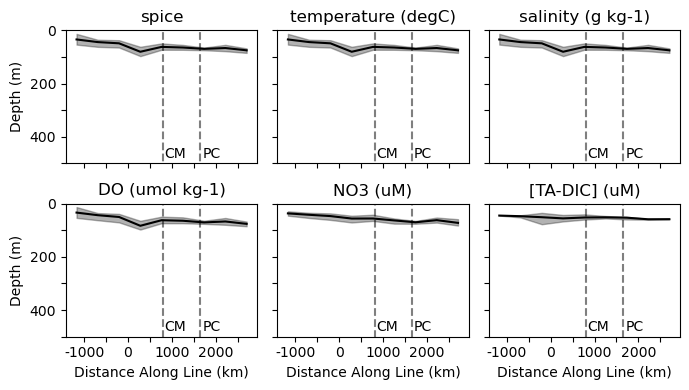

In [42]:
fig, ax = plt.subplots(2,3, figsize=(7, 4))
Dspice = plot_depth('spice', obs_cc, (0,0),yax=True)
Dtemp = plot_depth('temperature (degC)', obs_cc, (0,1))
Dsalt = plot_depth('salinity (g kg-1)', obs_cc, (0,2))
Ddo = plot_depth('DO (umol kg-1)', obs_cc, (1,0),yax=True,xax=True)
Dno3 = plot_depth('NO3 (uM)', obs_cc, (1,1),xax=True)
Dtadic = plot_depth('[TA-DIC] (uM)', obs_cc, (1,2),xax=True)

plt.tight_layout()

plt.savefig('./output/CCobsdepth.png')

In [43]:
# print difference in depth between the first and last bin
print(f'spice depth change = {Dspice[0]-Dspice[-1]}')
print(f'temp depth change = {Dtemp[0]-Dtemp[-1]}')
print(f'salt depth change = {Dsalt[0]-Dsalt[-1]}')
print(f'do depth change = {Ddo[0]-Ddo[-1]}')
print(f'no3 depth change = {Dno3[0]-Dno3[-1]}')
print(f'tadic depth change = {Dtadic[0]-Dtadic[-1]}')

spice depth change = -40.79217830057278
temp depth change = -40.79217830057278
salt depth change = -40.79217830057278
do depth change = -42.324858564852825
no3 depth change = -35.58657165812187
tadic depth change = -13.477243834223245


In [44]:
# check correlation between mean depth and the trends

print(f'spice: r = {pearsonr(spice,Dspice).statistic}, pvalue = {pearsonr(spice,Dspice).pvalue}')
print(f'temp: r = {pearsonr(temp,Dtemp).statistic}, pvalue = {pearsonr(temp,Dtemp).pvalue}')
print(f'salt: r = {pearsonr(salt,Dsalt).statistic}, pvalue = {pearsonr(salt,Dsalt).pvalue}')
print(f'do: r = {pearsonr(do,Ddo).statistic}, pvalue = {pearsonr(do,Ddo).pvalue}')
print(f'no3: r = {pearsonr(no3,Dno3).statistic}, pvalue = {pearsonr(no3,Dno3).pvalue}')
print(f'tadic: r = {pearsonr(tadic,Dtadic).statistic}, pvalue = {pearsonr(tadic,Dtadic).pvalue}')

spice: r = -0.44995684909843686, pvalue = 0.22426603882294238
temp: r = -0.6211880769018704, pvalue = 0.07417525082583581
salt: r = 0.657885952676756, pvalue = 0.05409137233962356
do: r = 0.45114577502006714, pvalue = 0.22289251735588972
no3: r = 0.18869504721174907, pvalue = 0.6268175520003184
tadic: r = nan, pvalue = nan


In [45]:
print_ratediff_NS_CI(obs_cc,depth_bin=1)


spice
Common depth range: 10–120 m
-1415 to -930 km & 0.0036 & 0.0043 & 1972-2023 & 3126
-930 to -445 km & 0.0050 & 0.0052 & 1972-2023 & 3517
-445 to 40 km & -0.0010 & 0.0025 & 1949-2023 & 4114
40 to 525 km & -0.0013 & 0.0020 & 1949-2022 & 32846
525 to 1010 km & -0.0016 & 0.0031 & 1949-2021 & 3320
1010 to 1495 km & 0.0003 & 0.0024 & 1949-2021 & 14544
1495 to 1980 km & 0.0006 & 0.0022 & 1949-2021 & 92692
1980 to 2465 km & -0.0074 & 0.0026 & 1949-2020 & 23624
2465 to 2950 km & 0.0023 & 0.0065 & 1949-2016 & 12902

temperature (degC)
Common depth range: 10–120 m
-1415 to -930 km & 0.0486 & 0.0167 & 1972-2023 & 3126
-930 to -445 km & 0.0520 & 0.0258 & 1972-2023 & 3517
-445 to 40 km & 0.0046 & 0.0135 & 1949-2023 & 4114
40 to 525 km & 0.0069 & 0.0092 & 1949-2022 & 32846
525 to 1010 km & -0.0002 & 0.0087 & 1949-2021 & 3320
1010 to 1495 km & 0.0022 & 0.0104 & 1949-2021 & 14544
1495 to 1980 km & 0.0078 & 0.0091 & 1949-2021 & 92692
1980 to 2465 km & -0.0382 & 0.0099 & 1949-2020 & 23624
2465 to 2